# 03. Время: тренд, сезонность и сходство рядов

Разбираемся, какие повторяющиеся изменения есть в продажах, одинаковы ли они у разных товаров и складов и помогают ли предсказывать следующий период.

**Один ряд** — количество продаж по дням для выбранной группы: всего бизнеса, склада, товара или фиксированного набора пар склад × артикул. Исходная гранулярность — день; часовых отметок в данных нет.

**Декомпозиция** разделяет ряд на плавный **тренд**, повторяющуюся **сезонность** и **остаток**, который эти компоненты не объяснили. Остаток может содержать события, ошибки учёта или ещё не найденную структуру.

Здесь важно отделить несколько эффектов:

- общий объём меняется вместе с числом известных товаров и складских пар;
- недельная сезонность может отличаться по товарам и годам;
- два полных года дают ограниченное основание для вывода о годовой сезонности;
- похожий общий рост двух рядов ещё не означает, что они одинаково реагируют по дням.

Основной анализ и все окна сравнения прогнозов ограничены **обучающим периодом до 2026-06-05**. Июньская валидация и июль в этом ноутбуке не используются. Компоненты декомпозиции вычисляются для описания истории, а не добавляются автоматически в FE.

Для запуска нужен пакет `statsmodels`; он добавлен в `requirements.txt`. В Jupyter выберите Python из подготовленной `.venv`.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


import sys,platform,importlib.metadata
from scipy import signal
from scipy.cluster.hierarchy import linkage,leaves_list
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import seasonal_decompose,STL,MSTL
from statsmodels.tsa.stattools import acf,pacf,adfuller,kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.forecasting.stl import STLForecast
OUT=ROOT/'data/artifacts/time_analysis';OUT.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
TRAIN_END=pd.Timestamp(manifest['train_end'])
sales=pd.read_parquet(PROCESSED/'sales_daily.parquet')
stock=pd.read_parquet(PROCESSED/'stock_daily.parquet')
sales=sales[sales.date.le(TRAIN_END)].copy();stock=stock[stock.date.le(TRAIN_END)].copy()
for f in [sales,stock]:
    for c in ['warehouse_name','article']:f[c]=f[c].astype(str)
calendar=pd.date_range(sales.date.min(),TRAIN_END,freq='D')
assert sales.quantity.ge(0).all()
assert not sales.duplicated(['date','warehouse_name','article']).any()
WEEKDAYS=['Пн','Вт','Ср','Чт','Пт','Сб','Вс']

def savefig(name):
    plt.tight_layout();plt.savefig(OUT/name,dpi=160,bbox_inches='tight');plt.show()

def strength(season,residual):
    season=np.asarray(season);residual=np.asarray(residual)
    keep=np.isfinite(season)&np.isfinite(residual)
    denominator=np.var(season[keep]+residual[keep])
    return float(max(0,1-np.var(residual[keep])/denominator)) if denominator>0 else np.nan

print('Период анализа:',calendar.min().date(),'—',calendar.max().date(),'; дней:',len(calendar))
print('Продажи:',f'{len(sales):,}','дневных ключей; склады:',sales.warehouse_name.nunique(),'; артикулы:',sales.article.nunique())

Период анализа: 2024-01-01 — 2026-06-05 ; дней: 887
Продажи: 882,105 дневных ключей; склады: 11 ; артикулы: 799


## 1. Рост числа пар и рост самих продаж

Сначала строим дневные ряды без смешивания строк. Пара считается известной с первого появления в продажах или остатках; в день прогноза она должна быть известна **до текущей даты**. Её первый день не включаем в анализ прогнозируемой суммы. Известные пары остаются в счётчике и после прекращения продаж — это не число реально доступных товаров.

Для известного набора есть точное разложение:

**общие продажи = число известных пар × доля пар с продажами × средний размер положительной продажи.**

Дополнительно фиксируем пары, известные до 2024-01-01, без отбора по их будущей успешности. Это постоянный состав для сравнения; он описывает старый ассортимент, а не весь бизнес. Пропущенные продажи после появления пары по прежнему допущению считаем нулём.

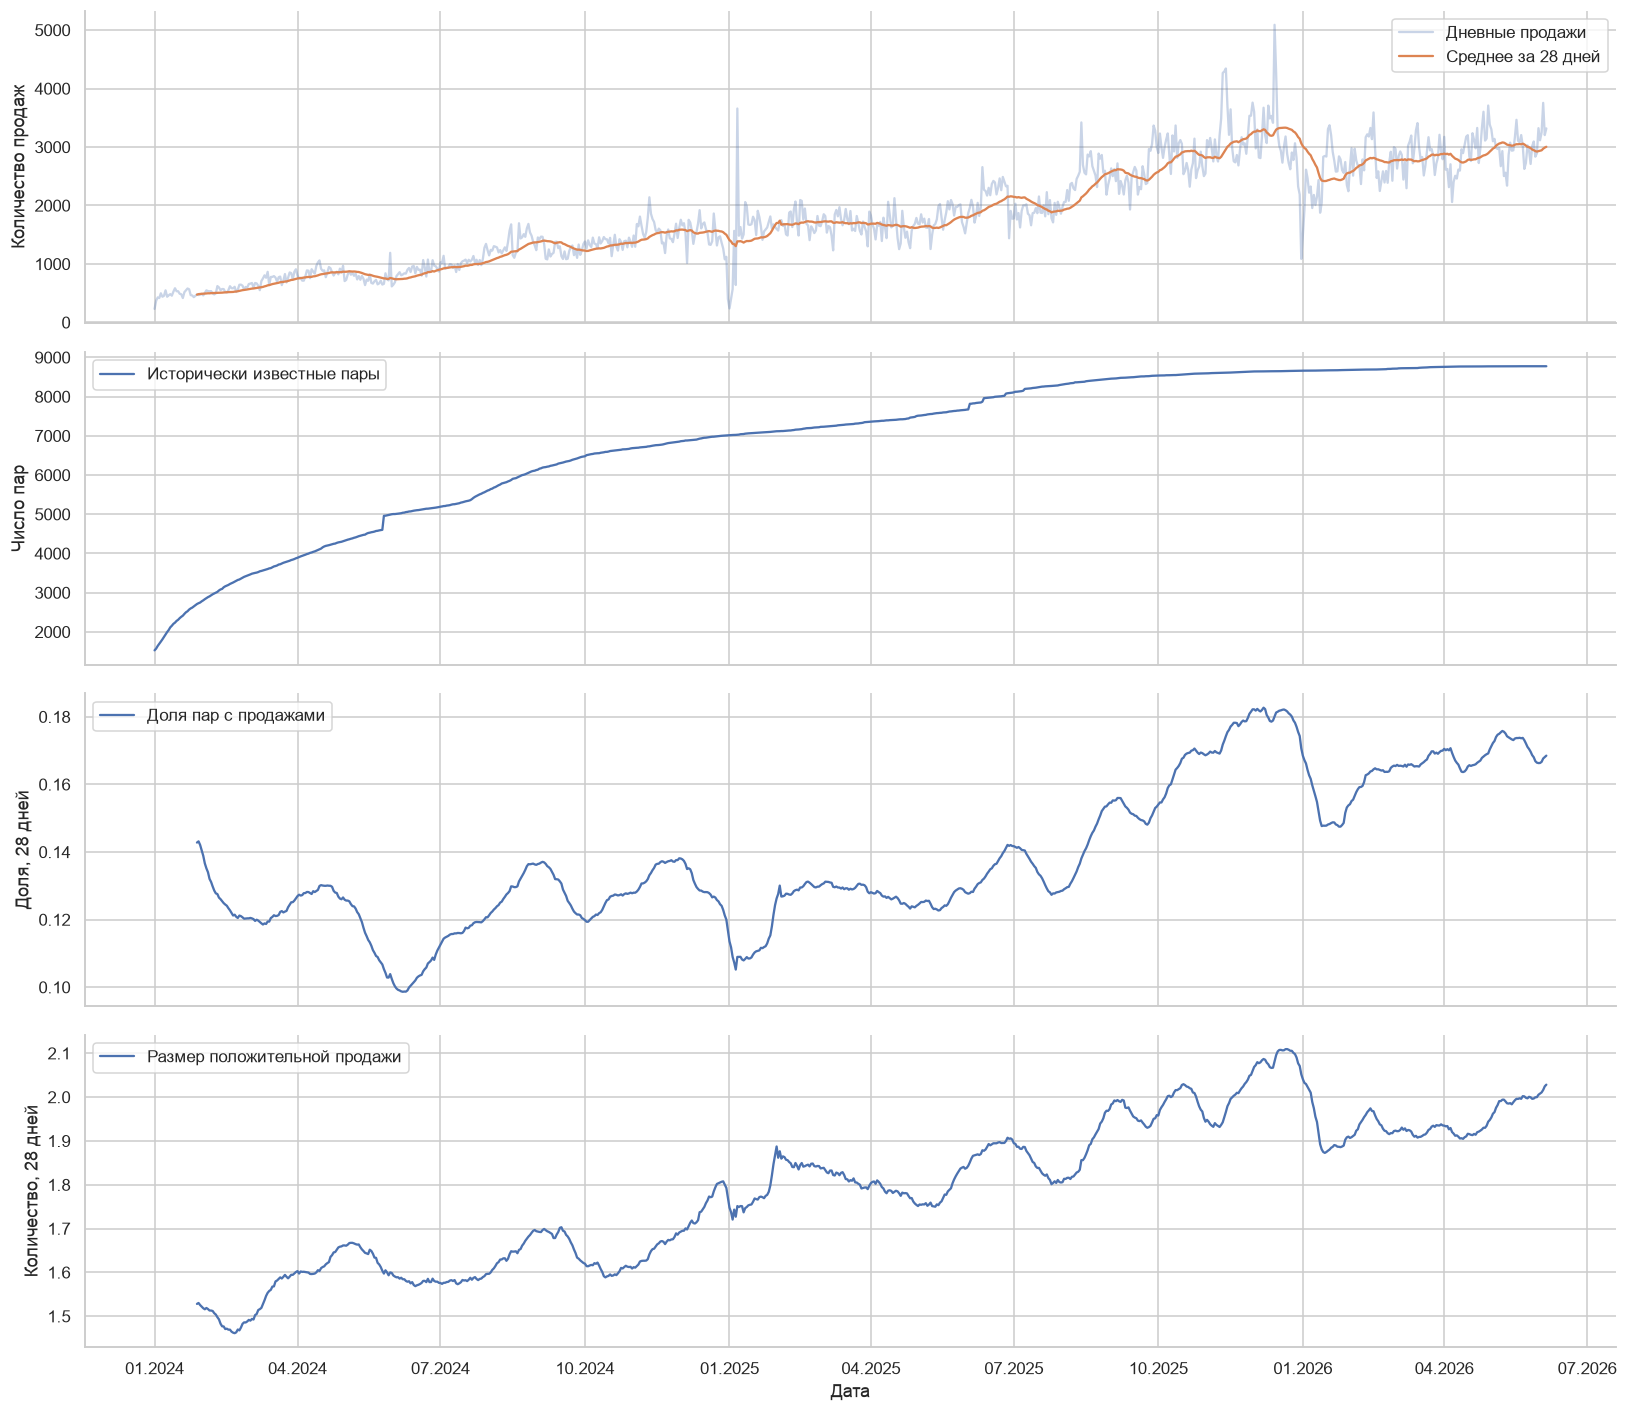

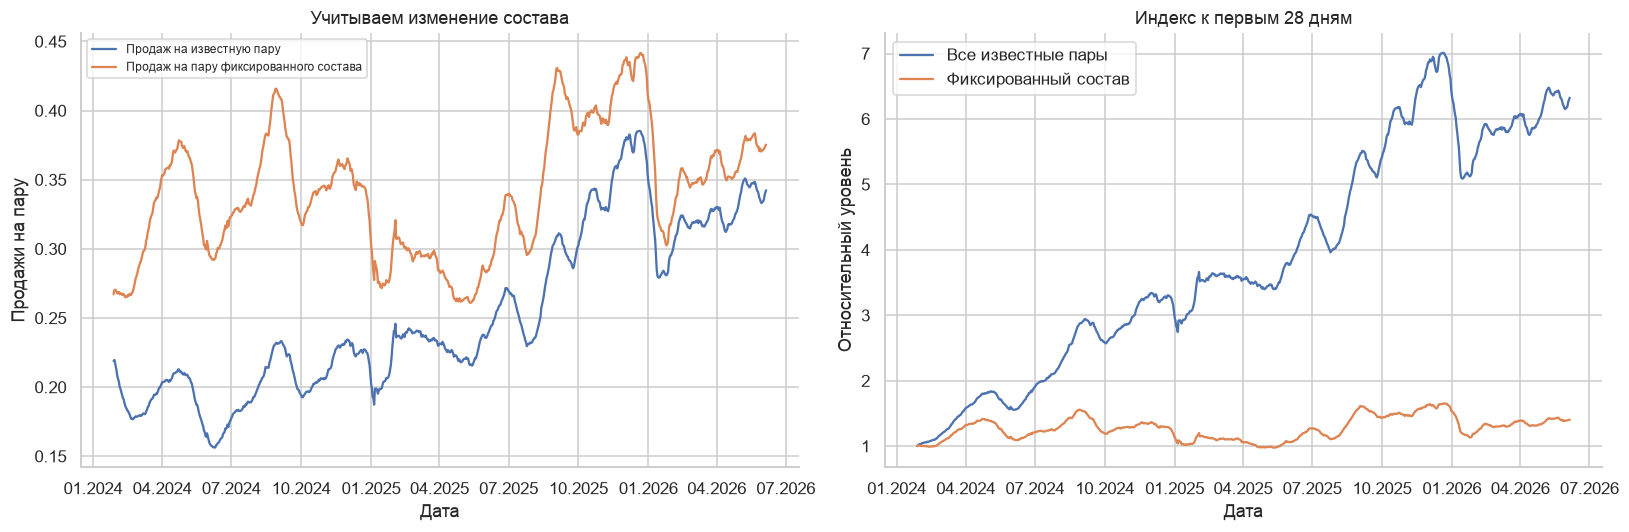

Пар в фиксированном составе: 1529 ; известных пар к концу: 8775


In [2]:
KEY=['date','warehouse_name','article'];PAIR=['warehouse_name','article']
first_seen=(pd.concat([sales[KEY],stock[KEY]],ignore_index=True).groupby(PAIR,observed=True).date.min().rename('first_seen').reset_index())
sales=sales.merge(first_seen,on=PAIR,how='left',validate='many_to_one')
eligible=sales[sales.date.gt(sales.first_seen)].copy()
known=np.searchsorted(np.sort(first_seen.first_seen.to_numpy(dtype='datetime64[ns]')),calendar.to_numpy(),side='left')
daily=pd.DataFrame(index=calendar)
daily['quantity']=eligible.groupby('date').quantity.sum().reindex(calendar,fill_value=0)
daily['raw_quantity']=sales.groupby('date').quantity.sum().reindex(calendar,fill_value=0)
daily['known_pairs']=known
daily['selling_pairs']=eligible.groupby('date').size().reindex(calendar,fill_value=0)
daily['sale_share']=daily.selling_pairs/daily.known_pairs
daily['size_when_sold']=daily.quantity/daily.selling_pairs.replace(0,np.nan)
daily['qty_per_known_pair']=daily.quantity/daily.known_pairs
cohort=first_seen[first_seen.first_seen.lt(calendar.min())].copy()
assert len(cohort)>0
old_sales=eligible.merge(cohort[PAIR],on=PAIR,how='inner',validate='many_to_one')
daily['fixed_cohort_quantity']=old_sales.groupby('date').quantity.sum().reindex(calendar,fill_value=0)
daily['qty_per_fixed_pair']=daily.fixed_cohort_quantity/len(cohort)
np.testing.assert_allclose(daily.quantity,daily.known_pairs*daily.sale_share*daily.size_when_sold,rtol=1e-10)
assert daily.index.equals(pd.date_range(daily.index.min(),daily.index.max(),freq='D'))
stock_time=stock.assign(positive=stock.stock_mean.gt(0),conflict=stock.stock_min.ne(stock.stock_max)).groupby('date').agg(
    stock_keys=('stock_mean','size'),positive_stock_share=('positive','mean'),stock_conflict_share=('conflict','mean'))
daily=daily.join(stock_time)
daily.rename_axis('date').to_csv(OUT/'daily_time_panel.csv')
SERIES={'all':daily.quantity.astype(float),'fixed':daily.fixed_cohort_quantity.astype(float)}
SERIES_LABELS={'all':'Все известные пары','fixed':'Фиксированный состав с начала 2024 года'}
fig,axes=plt.subplots(4,1,figsize=(15,13),sharex=True)
axes[0].plot(daily.index,daily.quantity,alpha=.3,label='Дневные продажи');axes[0].plot(daily.index,daily.quantity.rolling(28).mean(),label='Среднее за 28 дней');axes[0].set_ylabel('Количество продаж');axes[0].legend()
axes[1].plot(daily.index,daily.known_pairs,label='Исторически известные пары');axes[1].set_ylabel('Число пар');axes[1].legend()
axes[2].plot(daily.index,daily.sale_share.rolling(28).mean(),label='Доля пар с продажами');axes[2].set_ylabel('Доля, 28 дней');axes[2].legend()
axes[3].plot(daily.index,daily.size_when_sold.rolling(28).mean(),label='Размер положительной продажи');axes[3].set(ylabel='Количество, 28 дней',xlabel='Дата');axes[3].legend()
savefig('01_growth_components.png')
fig,axes=plt.subplots(1,2,figsize=(15,5))
for c,title in [('qty_per_known_pair','Продаж на известную пару'),('qty_per_fixed_pair','Продаж на пару фиксированного состава')]:
    axes[0].plot(daily.index,daily[c].rolling(28).mean(),label=title)
axes[0].set(title='Учитываем изменение состава',xlabel='Дата',ylabel='Продажи на пару');axes[0].legend(fontsize=8)
for c,title in [('quantity','Все известные пары'),('fixed_cohort_quantity','Фиксированный состав')]:
    v=daily[c].rolling(28).mean();axes[1].plot(daily.index,v/v.dropna().iloc[0],label=title)
axes[1].set(title='Индекс к первым 28 дням',xlabel='Дата',ylabel='Относительный уровень');axes[1].legend()
savefig('02_fixed_cohort.png')
print('Пар в фиксированном составе:',len(cohort),'; известных пар к концу:',int(daily.known_pairs.iloc[-1]))

## 2. Сравниваем способы декомпозиции

**Классическая аддитивная декомпозиция:** продажи = тренд + недельная компонента + остаток. Недельный рисунок фиксирован на всём участке, крайние значения тренда частично недоступны.

**STL:** плавно оценивает тренд и сезонность локально; рисунок может меняться со временем. Устойчивый вариант уменьшает влияние отдельных выбросов. Здесь период 7 дней, тренд сглаживается на масштабе 91 дня.

**STL для log1p:** сначала считаем log(1 + продажи). Это удобнее, если сезонный размах растёт вместе с уровнем. В этой шкале сумма компонент после обратного преобразования становится произведением для **1 + продажи**, а не точно для продаж.

**MSTL:** расширение STL для нескольких периодов — недели и 365 дней. В обучении лишь два полных календарных года; годовая компонента остаётся гипотезой. Период 365 приближённый: високосный день и календарные сдвиги могут влиять на оценку.

Центрированные методы используют обе стороны даты внутри исследуемой истории. Поэтому эти компоненты нельзя просто присоединить к строкам FE: это внесёт будущее в признаки. Здесь они описывают прошлое; для прогноза ниже каждый метод обучается заново только до своей границы.

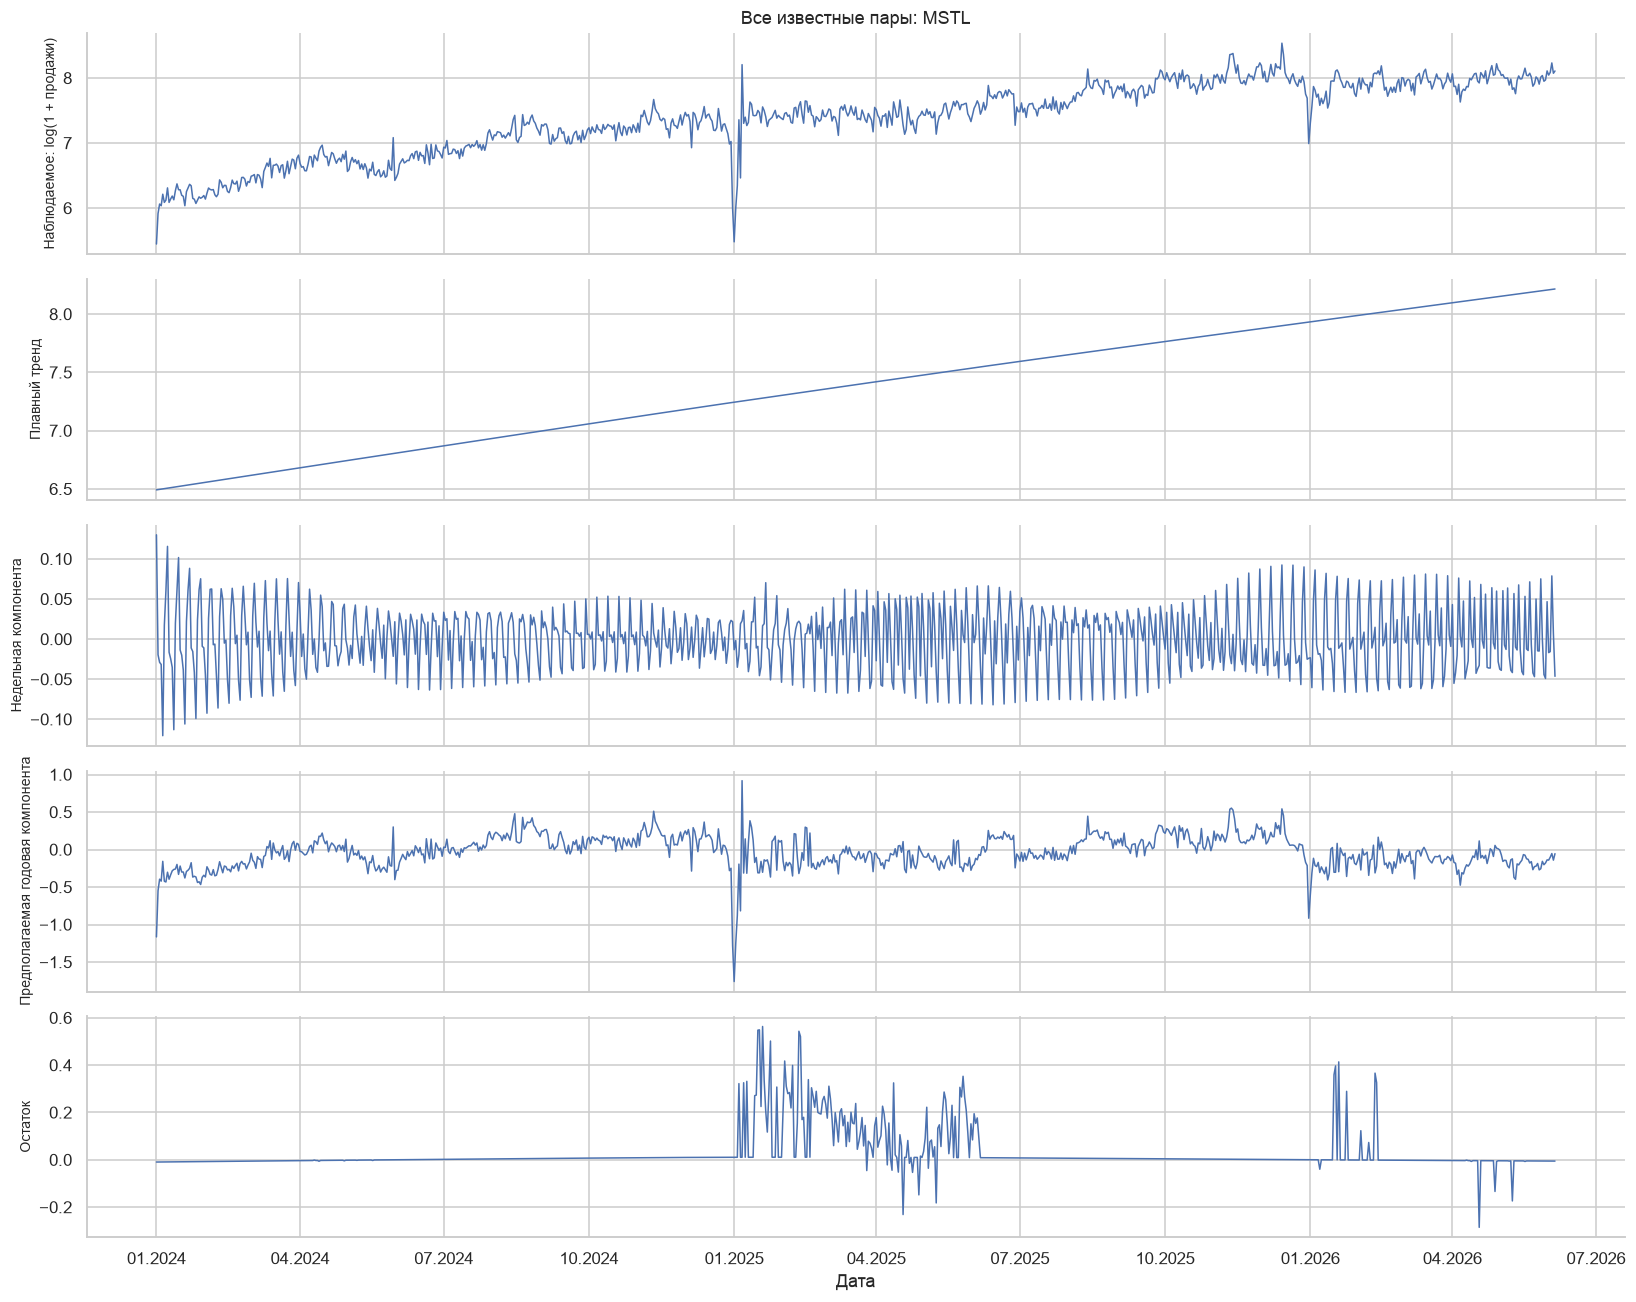

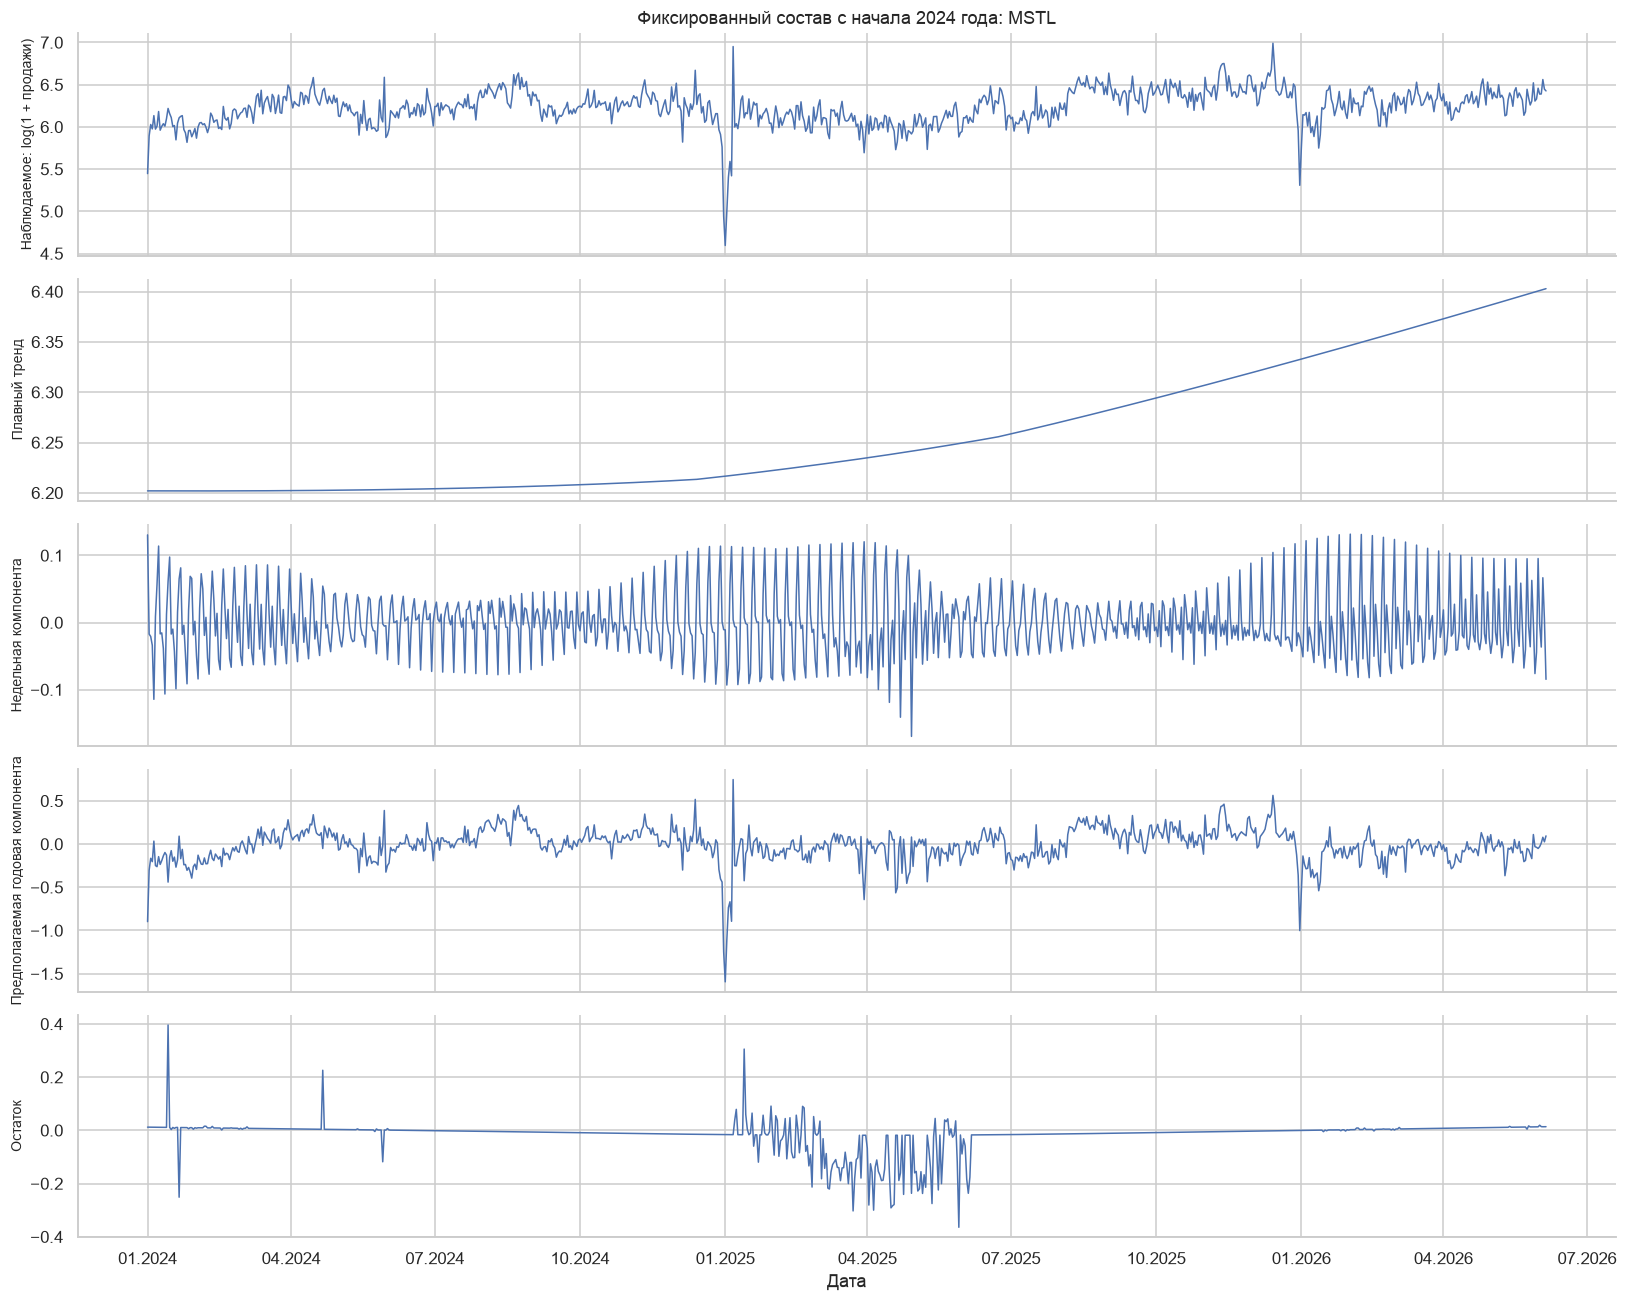

,Ряд,Метод,Шкала,Доступных дней,Разброс остатка,Описательная сила сезонности,"ACF остатка, лаг 7",Сила недельной компоненты,Сила годовой компоненты
0,Все известные пары,Классический недельный,штуки,881,186.2474,0.0716,0.0942,NaN,NaN
1,Все известные пары,STL недельный,штуки,887,290.7752,0.0478,0.1277,NaN,NaN
2,Все известные пары,STL недельный в log1p,log1p,887,0.1604,0.0595,0.0731,NaN,NaN
3,Все известные пары,MSTL: неделя и год,log1p,887,0.0856,0.8423,0.4486,0.1789,0.8376
4,Фиксированный состав с начала 2024 года,Классический недельный,штуки,881,51.9935,0.0575,0.0484,NaN,NaN
5,Фиксированный состав с начала 2024 года,STL недельный,штуки,887,73.0841,0.0817,0.0860,NaN,NaN
6,Фиксированный состав с начала 2024 года,STL недельный в log1p,log1p,887,0.1554,0.0711,0.0848,NaN,NaN
7,Фиксированный состав с начала 2024 года,MSTL: неделя и год,log1p,887,0.0552,0.9222,0.4073,0.4324,0.9199


In [3]:
decompositions={};decomposition_rows=[]
for key,y in SERIES.items():
    classic=seasonal_decompose(y,model='additive',period=7)
    weekly=STL(y,period=7,seasonal=13,trend=91,robust=True).fit()
    weekly_log=STL(np.log1p(y),period=7,seasonal=13,trend=91,robust=True).fit()
    multi=MSTL(np.log1p(y),periods=(7,365),windows=(13,7),stl_kwargs={'robust':True}).fit()
    decompositions[key]={'classic':classic,'stl':weekly,'log_stl':weekly_log,'mstl':multi}
    for method,result,scale in [('Классический недельный',classic,'штуки'),('STL недельный',weekly,'штуки'),
                                 ('STL недельный в log1p',weekly_log,'log1p'),('MSTL: неделя и год',multi,'log1p')]:
        seasonal=result.seasonal
        components=seasonal.sum(axis=1) if isinstance(seasonal,pd.DataFrame) else seasonal
        expected=y if scale=='штуки' else np.log1p(y)
        rebuilt=np.asarray(result.trend)+np.asarray(components)+np.asarray(result.resid)
        mask=np.isfinite(rebuilt)
        np.testing.assert_allclose(rebuilt[mask],np.asarray(expected)[mask],rtol=1e-8,atol=1e-8)
        row={'series':SERIES_LABELS[key],'method':method,'scale':scale,'usable_rows':int(mask.sum()),
             'residual_std':float(np.nanstd(result.resid)),
             'season_strength':strength(components,result.resid),
             'residual_acf7':float(acf(pd.Series(result.resid).dropna(),nlags=7,fft=True)[7])}
        if isinstance(seasonal,pd.DataFrame):
            row['weekly_strength']=strength(seasonal.iloc[:,0],result.resid)
            row['annual_strength']=strength(seasonal.iloc[:,1],result.resid)
        decomposition_rows.append(row)
    m=multi
    fig,axes=plt.subplots(5,1,figsize=(15,12),sharex=True)
    for ax,values,title in [(axes[0],np.log1p(y),'Наблюдаемое: log(1 + продажи)'),(axes[1],m.trend,'Плавный тренд'),
                            (axes[2],m.seasonal.iloc[:,0],'Недельная компонента'),(axes[3],m.seasonal.iloc[:,1],'Предполагаемая годовая компонента'),
                            (axes[4],m.resid,'Остаток')]:
        ax.plot(y.index,values,lw=1);ax.set_ylabel(title,fontsize=9)
    axes[0].set_title(SERIES_LABELS[key]+': MSTL');axes[-1].set_xlabel('Дата');savefig(f'03_mstl_{key}.png')
    pd.DataFrame({'observed':np.log1p(y),'trend':m.trend,'weekly':m.seasonal.iloc[:,0],
                  'annual':m.seasonal.iloc[:,1],'residual':m.resid}).to_csv(OUT/f'decomposition_{key}.csv',index_label='date')
decomposition_table=pd.DataFrame(decomposition_rows)
decomposition_table.to_csv(OUT/'decomposition_comparison.csv',index=False)
display_ru(decomposition_table.rename(columns={'series':'Ряд','method':'Метод','scale':'Шкала','usable_rows':'Доступных дней',
    'residual_std':'Разброс остатка','season_strength':'Описательная сила сезонности','residual_acf7':'ACF остатка, лаг 7',
    'weekly_strength':'Сила недельной компоненты','annual_strength':'Сила годовой компоненты'}).round(4))

### Как читать силу сезонности

Показатель `max(0, 1 − Var(остаток) / Var(сезонность + остаток))` описывает долю изменчивости, которую в выбранной декомпозиции забрала сезонная компонента. Это не p-value, не причинный эффект и не качество будущего прогноза. Гибкая декомпозиция способна показать красивую сезонность и на нестабильной истории.

Разброс остатков в штуках и log1p напрямую не сравнивается. Для выбора прогнозного метода важнее отдельная проверка на будущих относительно обучения отрезках.

Устойчивый STL может оставить больший остаток, чем обычное разложение: он намеренно меньше подстраивается под выбросы. Поэтому минимальный остаток внутри истории не является достаточным критерием выбора.

На короткой истории MSTL может почти полностью перенести нерегулярные колебания в годовую компоненту. Почти нулевой остаток на длинном участке здесь скорее требует осторожности, чем подтверждает найденный закон. В нашем ряду только 2,4 годовых цикла.

## 3. Недельный рисунок и его устойчивость

Убираем плавный тренд в log1p и сравниваем дни недели. Затем смотрим, сохраняется ли рисунок в разные годы. Отдельный график неопределённости строим по целым неделям: внутри недели убираем её средний уровень, а при повторных выборках переносим блоки по четыре недели. Так соседние дни не считаются независимыми наблюдениями.

Интервалы показывают приблизительную неопределённость среднего эффекта каждого дня. Они точечные, а не одновременные для всех дней; зависимость между длинными блоками может сохраняться.

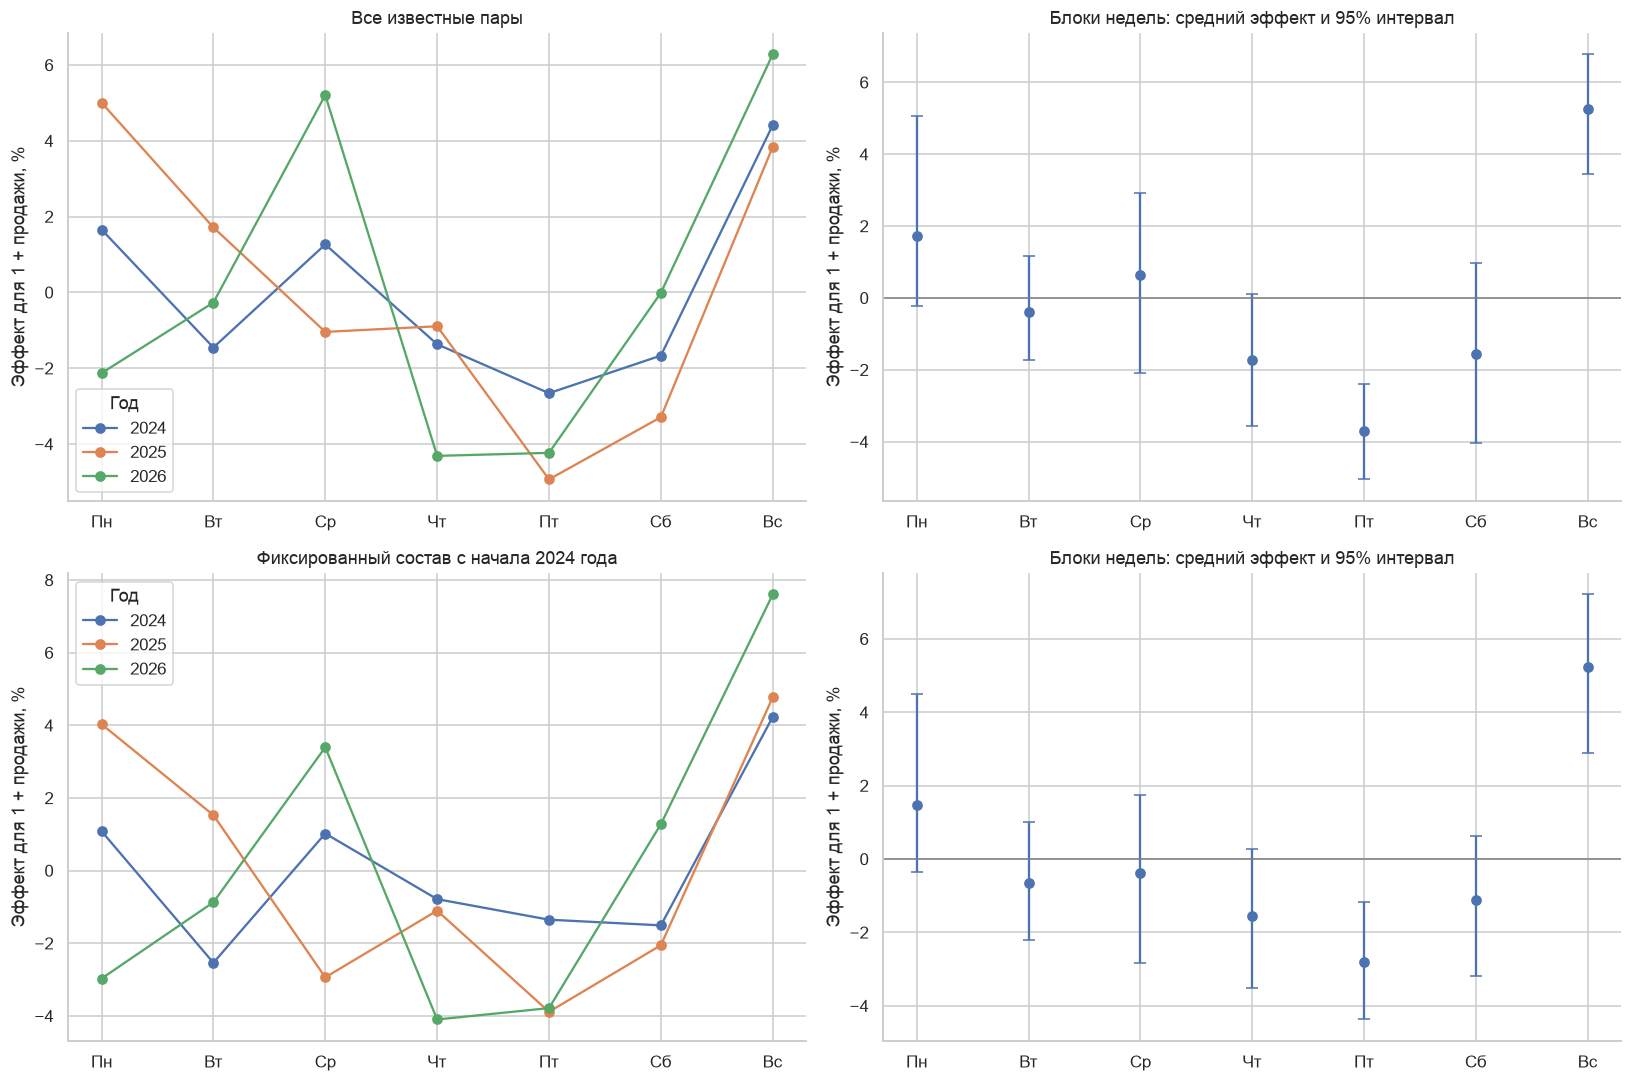

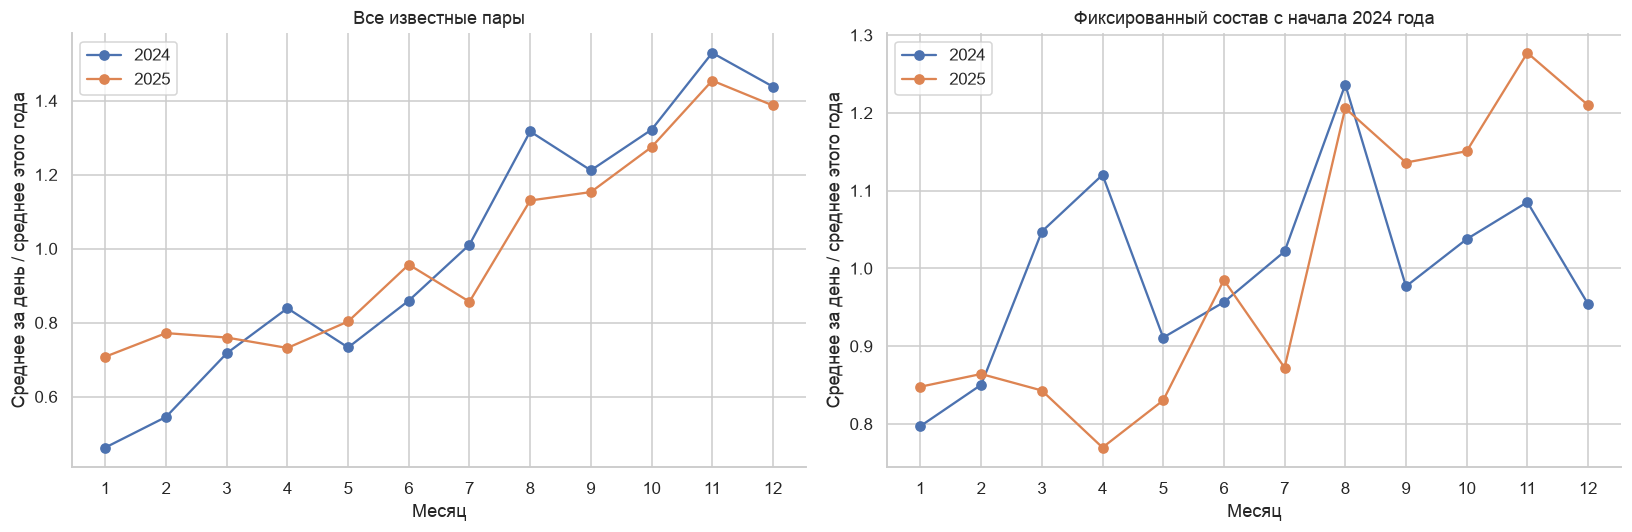

In [4]:
weekly_profiles=[];bootstrap_rows=[]
fig,axes=plt.subplots(2,2,figsize=(15,10))
for row,(key,y) in enumerate(SERIES.items()):
    relative=np.log1p(y)-decompositions[key]['log_stl'].trend
    frame=pd.DataFrame({'effect':relative,'dow':y.index.dayofweek,'year':y.index.year},index=y.index)
    profile=frame.groupby(['year','dow']).effect.mean().unstack('dow')
    profile=profile.sub(profile.mean(axis=1),axis=0)
    for year,values in profile.iterrows():axes[row,0].plot(np.arange(7),100*np.expm1(values),'o-',label=str(year))
    axes[row,0].set(xticks=np.arange(7),xticklabels=WEEKDAYS,title=SERIES_LABELS[key],ylabel='Эффект для 1 + продажи, %');axes[row,0].legend(title='Год')
    for year,values in profile.iterrows():
        for dow,value in values.items():weekly_profiles.append({'series':key,'year':int(year),'weekday':int(dow),'log_effect':float(value)})
    weeks=pd.DataFrame({'date':y.index,'value':np.log1p(y).to_numpy()})
    weeks['week']=weeks.date.dt.to_period('W-SUN');weeks['dow']=weeks.date.dt.dayofweek
    mat=weeks.pivot(index='week',columns='dow',values='value').dropna().to_numpy()
    mat=mat-mat.mean(axis=1,keepdims=True)
    rng=np.random.default_rng(SEED);boot=[];n=len(mat);block=4
    for _ in range(1000):
        starts=rng.integers(0,n-block+1,size=int(np.ceil(n/block)))
        ids=np.concatenate([np.arange(s,s+block) for s in starts])[:n]
        boot.append(mat[ids].mean(axis=0))
    mean=mat.mean(axis=0);low,high=np.quantile(boot,[.025,.975],axis=0)
    axes[row,1].errorbar(np.arange(7),100*np.expm1(mean),
        yerr=np.array([100*(np.expm1(mean)-np.expm1(low)),100*(np.expm1(high)-np.expm1(mean))]),fmt='o',capsize=4)
    axes[row,1].axhline(0,color='gray',lw=1);axes[row,1].set(xticks=np.arange(7),xticklabels=WEEKDAYS,title='Блоки недель: средний эффект и 95% интервал',ylabel='Эффект для 1 + продажи, %')
    for dow in range(7):bootstrap_rows.append({'series':key,'weekday':dow,'effect_pct':100*np.expm1(mean[dow]),
                                             'low_pct':100*np.expm1(low[dow]),'high_pct':100*np.expm1(high[dow])})
savefig('04_weekly_stability.png')
pd.DataFrame(weekly_profiles).to_csv(OUT/'weekly_profiles_by_year.csv',index=False)
pd.DataFrame(bootstrap_rows).to_csv(OUT/'weekly_effect_intervals.csv',index=False)
# Годовой рисунок сравниваем только по двум полным календарным годам.
annual=[];fig,axes=plt.subplots(1,2,figsize=(15,5))
for ax,(key,y) in zip(axes,SERIES.items()):
    frame=pd.DataFrame({'quantity':y,'year':y.index.year,'month':y.index.month})
    complete=[year for year,g in frame.groupby('year') if len(g)==(366 if pd.Timestamp(year,12,31).is_leap_year else 365)]
    for year in complete:
        g=frame[frame.year.eq(year)]
        monthly=g.groupby('month').quantity.mean()/g.quantity.mean()
        ax.plot(monthly.index,monthly,'o-',label=str(year))
        for month,value in monthly.items():annual.append({'series':key,'year':year,'month':month,'relative_daily_quantity':value})
    ax.set(title=SERIES_LABELS[key],xlabel='Месяц',ylabel='Среднее за день / среднее этого года',xticks=np.arange(1,13));ax.legend()
savefig('05_annual_calendar_profiles.png')
pd.DataFrame(annual).to_csv(OUT/'annual_month_profiles.csv',index=False)

## 4. Автокорреляция, спектр и стационарность

**ACF** показывает связь ряда с его собственными прошлыми значениями. **PACF** пытается отделить прямую связь выбранного лага от промежуточных лагов. Рост уровня может создавать высокую корреляцию почти со всеми прошлыми датами, поэтому рядом показываем дневные изменения и остатки STL.

**Спектр** ищет повторения разных длин. Перед расчётом убираем линейный тренд из log1p. Вертикальные линии 7, 30,4 и 365 дней — ориентиры, а не заранее доказанные периоды. При короткой истории годовые пики имеют низкое разрешение; календарный месяц не равен фиксированному числу дней.

**Стационарность** означает стабильность некоторых статистических свойств во времени. У ADF нулевая гипотеза — единичный корень; у KPSS — стационарность вокруг выбранного уровня или тренда. Их p-value зависит от спецификации. Тесты на уровне ряда и после разностей — диагностика, а не автоматическое указание преобразовать целевую переменную.

Тест Льюнга–Бокса проверяет отсутствие автокорреляции остатков на выбранных лагах. Малое p-value говорит о неучтённой временной структуре в рамках теста; оно не выбирает лучшую модель.

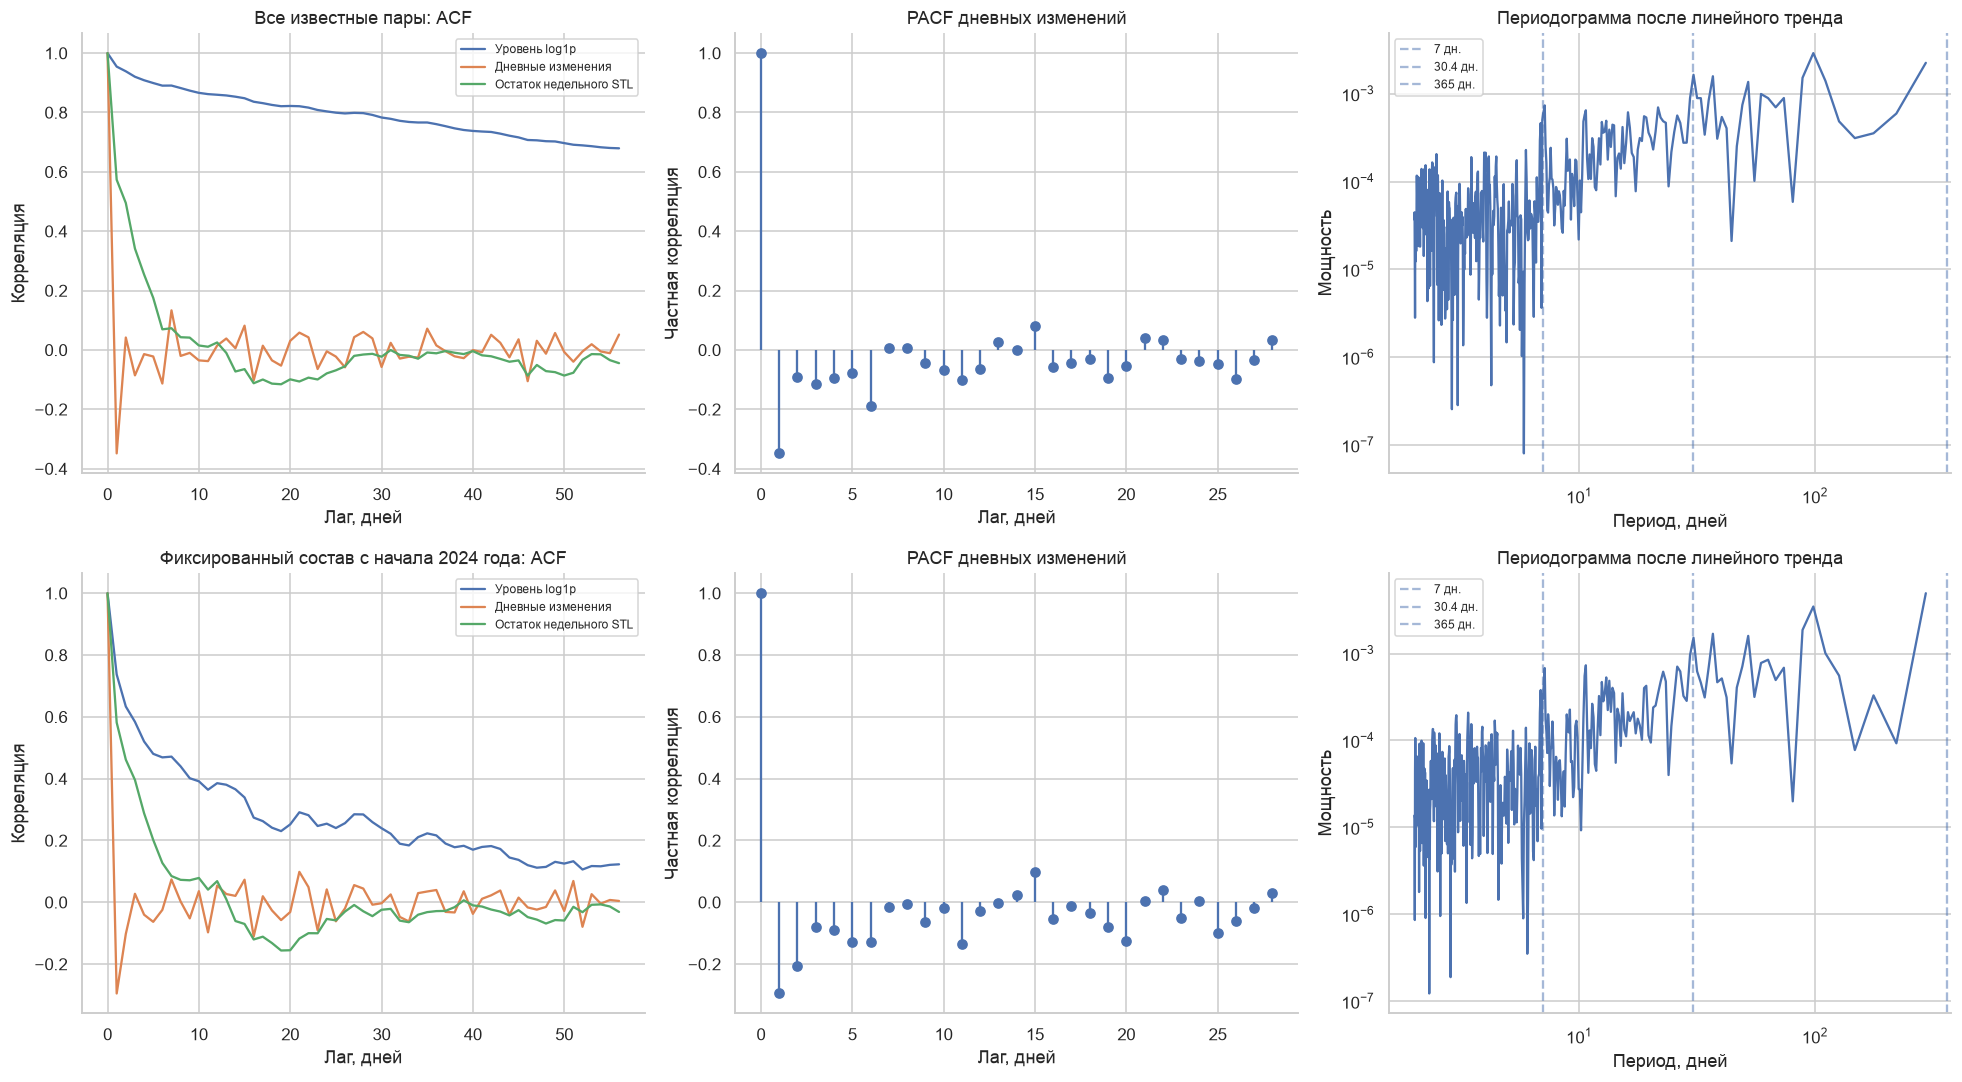

,Ряд,Преобразование,Уровень или тренд в тесте,ADF_p,ADF_lags,KPSS_p,KPSS_lags
0,Все известные пары,Уровень log1p,уровень и тренд,0.08130,26,0.01,17
1,Все известные пары,Дневная разность,уровень,0.00000,25,0.10,36
2,Все известные пары,Недельная разность,уровень,0.00000,28,0.10,13
3,Фиксированный состав с начала 2024 года,Уровень log1p,уровень и тренд,0.08823,26,0.01,17
4,Фиксированный состав с начала 2024 года,Дневная разность,уровень,0.00000,25,0.10,38
5,Фиксированный состав с начала 2024 года,Недельная разность,уровень,0.00000,28,0.10,13


In [5]:
stationarity_rows=[];spectral_rows=[];ljung_rows=[]
fig,axes=plt.subplots(2,3,figsize=(18,10))
for row,(key,y) in enumerate(SERIES.items()):
    logy=np.log1p(y);difference=logy.diff().dropna();resid=decompositions[key]['log_stl'].resid
    for values,label in [(logy,'Уровень log1p'),(difference,'Дневные изменения'),(resid,'Остаток недельного STL')]:
        values=pd.Series(values).dropna();a=acf(values,nlags=56,fft=True)
        axes[row,0].plot(np.arange(len(a)),a,label=label)
    axes[row,0].set(title=SERIES_LABELS[key]+': ACF',xlabel='Лаг, дней',ylabel='Корреляция');axes[row,0].legend(fontsize=8)
    p=pacf(difference,nlags=28,method='ywm')
    axes[row,1].stem(np.arange(len(p)),p,basefmt=' ');axes[row,1].set(title='PACF дневных изменений',xlabel='Лаг, дней',ylabel='Частная корреляция')
    frequency,power=signal.periodogram(signal.detrend(logy,type='linear'),window='hann',scaling='spectrum')
    keep=(frequency>0)&(1/np.maximum(frequency,1e-12)>=2)&(1/np.maximum(frequency,1e-12)<=400)
    periods=1/frequency[keep];powers=power[keep]
    axes[row,2].plot(periods,powers);axes[row,2].set(xscale='log',yscale='log',title='Периодограмма после линейного тренда',xlabel='Период, дней',ylabel='Мощность')
    for period in [7,30.4,365]:axes[row,2].axvline(period,ls='--',alpha=.5,label=f'{period:g} дн.')
    axes[row,2].legend(fontsize=8)
    peaks,_=signal.find_peaks(powers)
    for idx in sorted(peaks,key=lambda i:powers[i],reverse=True)[:8]:spectral_rows.append({'series':key,'period_days':float(periods[idx]),'power':float(powers[idx])})
    for label,values,regression in [('Уровень log1p',logy,'ct'),('Дневная разность',logy.diff().dropna(),'c'),('Недельная разность',logy.diff(7).dropna(),'c')]:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            adf=adfuller(values,maxlag=28,autolag='AIC',regression=regression)
            kp=kpss(values,regression=regression,nlags='auto')
        stationarity_rows.append({'series':SERIES_LABELS[key],'transformation':label,'regression':regression,
                                  'ADF_p':adf[1],'ADF_lags':adf[2],'KPSS_p':kp[1],'KPSS_lags':kp[2],
                                  'warning':' | '.join(str(w.message) for w in caught)})
    for method in ['log_stl','mstl']:
        table=acorr_ljungbox(decompositions[key][method].resid,lags=[7,28,56],return_df=True)
        for lag,r in table.iterrows():ljung_rows.append({'series':key,'method':method,'lag':int(lag),'statistic':r.lb_stat,'p_value':r.lb_pvalue})
savefig('06_acf_pacf_spectrum.png')
stationarity=pd.DataFrame(stationarity_rows);stationarity.to_csv(OUT/'stationarity_tests.csv',index=False)
pd.DataFrame(spectral_rows).to_csv(OUT/'spectral_peaks.csv',index=False)
pd.DataFrame(ljung_rows).to_csv(OUT/'residual_autocorrelation_tests.csv',index=False)
display_ru(stationarity.drop(columns='warning').assign(regression=stationarity.regression.map({'c':'уровень','ct':'уровень и тренд'})).rename(columns={'series':'Ряд','transformation':'Преобразование','regression':'Уровень или тренд в тесте'}).round(5))

## 5. Сравниваем склады: совпадение роста и совпадение изменений

Первая корреляционная матрица сравнивает log1p уровней. Вторая — дневные изменения log1p. Если общие уровни похожи, а изменения почти независимы, сходство могло объясняться общим ростом. Все сравнения используют один календарь.

Дополнительно сравним форму недельных рядов через **DTW**: метод допускает локальное растяжение времени. Ограничиваем сдвиг двумя неделями. Это описательная мера сходства, которая может скрывать различия календарных дат; она не доказывает общую причину продаж и не задаёт готовый признак.

Иерархическая группировка рядом с DTW только упорядочивает близкие ряды. Недельные профили складов показываем отдельно в реальных днях недели.

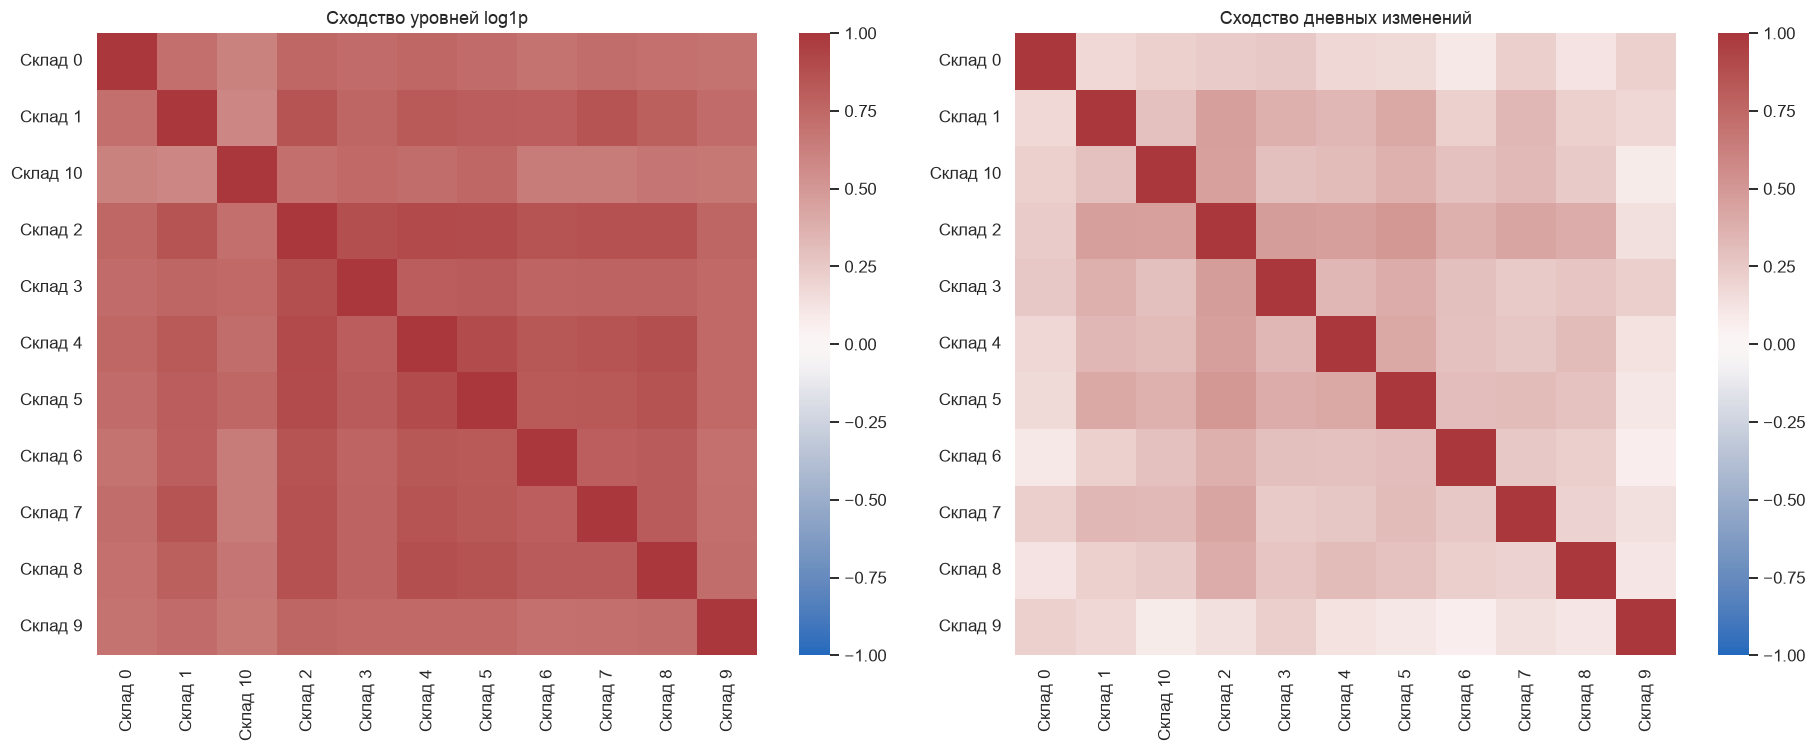

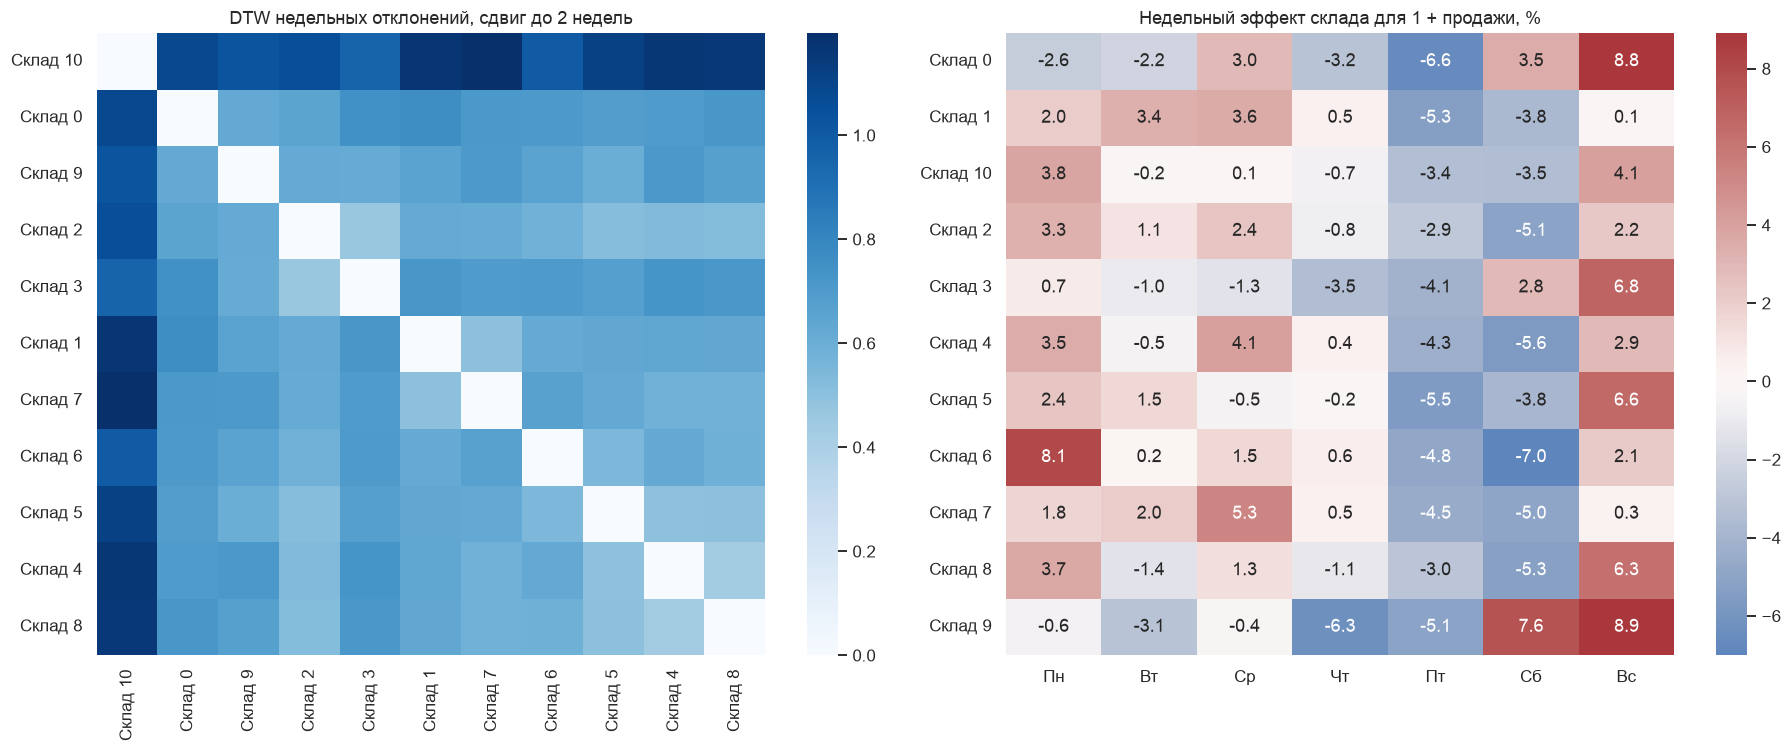

In [6]:
warehouse=eligible.pivot_table(index='date',columns='warehouse_name',values='quantity',aggfunc='sum',observed=True).reindex(calendar).fillna(0)
warehouse_first=first_seen.groupby('warehouse_name').first_seen.min()
# Для матриц используем общий участок, когда все склады уже известны.
common_start=max(calendar.min(),warehouse_first.max()+pd.Timedelta(days=1))
warehouse=warehouse.loc[common_start:]
assert len(warehouse)>365
level_corr=np.log1p(warehouse).corr();change_corr=np.log1p(warehouse).diff().dropna().corr()
fig,axes=plt.subplots(1,2,figsize=(17,7))
for ax,table,title in [(axes[0],level_corr,'Сходство уровней log1p'),(axes[1],change_corr,'Сходство дневных изменений')]:
    sns.heatmap(table.rename(index=identifier_label,columns=identifier_label),vmin=-1,vmax=1,cmap='vlag',ax=ax)
    ax.set_title(title);ax.set_xlabel('');ax.set_ylabel('')
savefig('07_warehouse_correlations.png')
level_corr.to_csv(OUT/'warehouse_level_correlations.csv');change_corr.to_csv(OUT/'warehouse_change_correlations.csv')
weekly=warehouse.resample('W-SUN').sum()
counts=warehouse.iloc[:,0].resample('W-SUN').count();weekly=weekly.loc[counts.eq(7)]
log_week=np.log1p(weekly)
# Убираем медленный уровень с помощью только прошлых недель, затем стандартизируем форму.
shape=(log_week-log_week.rolling(8,min_periods=4).mean().shift(1)).dropna()
z=(shape-shape.mean())/shape.std(ddof=0)

def dtw_distance(a,b,band=2):
    n=len(a);cost=np.full((n+1,n+1),np.inf);cost[0,0]=0
    for i in range(1,n+1):
        for j in range(max(1,i-band),min(n,i+band)+1):
            cost[i,j]=(a[i-1]-b[j-1])**2+min(cost[i-1,j],cost[i,j-1],cost[i-1,j-1])
    return float(np.sqrt(cost[n,n]/n))

names=z.columns.tolist();distance=np.zeros((len(names),len(names)))
for i in range(len(names)):
    for j in range(i):distance[i,j]=distance[j,i]=dtw_distance(z.iloc[:,i].to_numpy(),z.iloc[:,j].to_numpy())
assert np.allclose(distance,distance.T) and np.isfinite(distance).all()
order=leaves_list(linkage(squareform(distance,checks=True),method='average'))
dtw_table=pd.DataFrame(distance,index=names,columns=names)
dtw_table.to_csv(OUT/'warehouse_dtw_distances.csv')
profiles=[]
for wh in warehouse:
    y=warehouse[wh];r=STL(np.log1p(y),period=7,seasonal=13,trend=91,robust=True).fit()
    profile=pd.Series(np.log1p(y)-r.trend,index=y.index).groupby(y.index.dayofweek).mean()
    profile=profile-profile.mean()
    profiles.append(pd.Series(100*np.expm1(profile),name=wh))
warehouse_profile=pd.DataFrame(profiles)
warehouse_profile.to_csv(OUT/'warehouse_weekday_profiles.csv')
fig,axes=plt.subplots(1,2,figsize=(17,7))
sns.heatmap(dtw_table.iloc[order,order].rename(index=identifier_label,columns=identifier_label),cmap='Blues',ax=axes[0]);axes[0].set_title('DTW недельных отклонений, сдвиг до 2 недель')
p=warehouse_profile.copy();p.index=[identifier_label(x) for x in p.index];p.columns=WEEKDAYS
sns.heatmap(p,center=0,cmap='vlag',annot=True,fmt='.1f',ax=axes[1]);axes[1].set_title('Недельный эффект склада для 1 + продажи, %')
for ax in axes:ax.set_xlabel('');ax.set_ylabel('')
savefig('08_warehouse_dtw_and_week.png')

## 6. Товары: редкость продаж и недельная форма

У редкого товара красивый недельный рисунок может оказаться случайностью нескольких продаж. Для всех товаров считаем:

- **ADI:** число наблюдаемых дней / число дней с продажами; больше — события реже;
- **CV²:** квадрат коэффициента вариации положительных количеств; больше — размер продажи нестабильнее.

Границы ADI = 1,32 и CV² = 0,49 — распространённые эвристики описания прерывистого спроса. Они не являются подобранными порогами нашей задачи. Новые товары не получают искусственные нули до первого наблюдения.

Для сравнения формы берём товары с минимум годом истории и 60 днями продаж **в обучении**. Группируем по семи средним значениям дней недели, нормированным на среднее этих семи значений. Число групп заранее фиксируем равным четырём; это иллюстрация различий, а не найденная «истинная» классификация товаров.

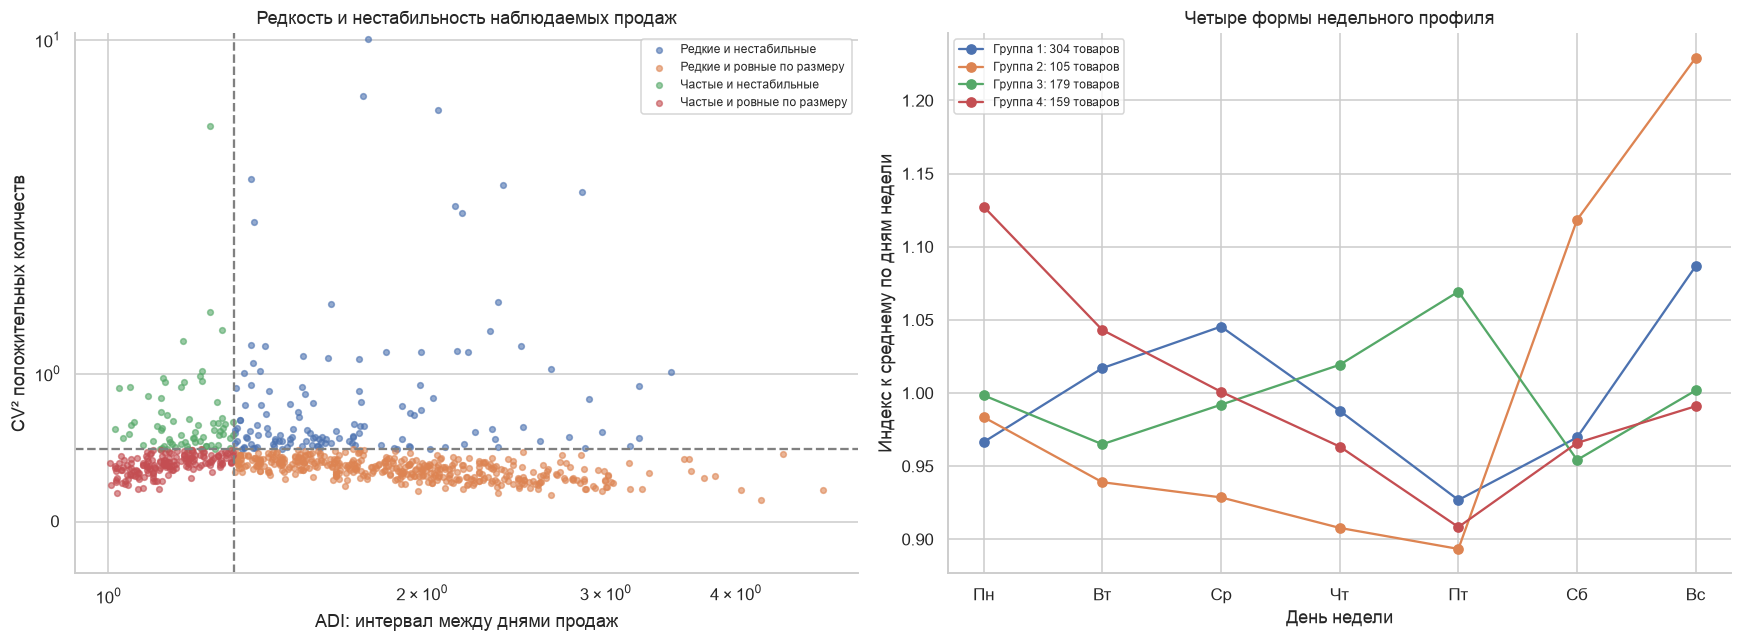

,Группа,Товаров,Ближайшие к центру примеры
0,1,304,"Артикул 580, Артикул 116, Артикул 59, Артикул ..."
1,2,105,"Артикул 327, Артикул 178, Артикул 716, Артикул..."
2,3,179,"Артикул 245, Артикул 419, Артикул 431, Артикул..."
3,4,159,"Артикул 208, Артикул 483, Артикул 244, Артикул..."


Silhouette: 0.111 ; ближе к 1 — группы лучше разделены, около 0 — формы перекрываются.


In [7]:
article=eligible.pivot_table(index='date',columns='article',values='quantity',aggfunc='sum',observed=True).reindex(calendar).fillna(0)
article_first=first_seen.groupby('article').first_seen.min()
for a in article:article.loc[article.index <= article_first[a],a]=np.nan
article_rows=[]
for a in article:
    y=article[a].dropna();positive=y[y.gt(0)]
    mean=positive.mean();cv2=positive.var(ddof=1)/mean**2 if len(positive)>1 and mean>0 else np.nan
    adi=len(y)/len(positive) if len(positive)>0 else np.nan
    kind='Недостаточно продаж'
    if np.isfinite(adi) and np.isfinite(cv2):
        kind=('Редкие' if adi>=1.32 else 'Частые')+(' и нестабильные' if cv2>=.49 else ' и ровные по размеру')
    article_rows.append({'article':a,'observed_days':len(y),'positive_days':len(positive),'quantity':float(y.sum()),'ADI':adi,'CV2':cv2,'type':kind})
article_stats=pd.DataFrame(article_rows).set_index('article')
article_stats.to_csv(OUT/'article_intermittency.csv')
fig,axes=plt.subplots(1,2,figsize=(16,6))
for kind,g in article_stats.groupby('type'):
    axes[0].scatter(g.ADI,g.CV2,s=14,alpha=.6,label=kind)
axes[0].axvline(1.32,ls='--',color='gray');axes[0].axhline(.49,ls='--',color='gray')
axes[0].set(xscale='log',yscale='symlog',xlabel='ADI: интервал между днями продаж',ylabel='CV² положительных количеств',title='Редкость и нестабильность наблюдаемых продаж');axes[0].legend(fontsize=8)
selected=article_stats.query('observed_days >= 365 and positive_days >= 60').index
profile=article[selected].groupby(article.index.dayofweek).mean().T
profile=profile.div(profile.mean(axis=1),axis=0).dropna()
assert len(profile)>8
clusterer=KMeans(n_clusters=4,n_init=20,random_state=SEED)
labels=clusterer.fit_predict(profile)
profiles=profile.copy();profiles['cluster']=labels
profiles.to_csv(OUT/'article_weekday_clusters.csv')
for cluster in range(4):
    center=profile.iloc[labels==cluster].mean()
    axes[1].plot(np.arange(7),center,'o-',label=f'Группа {cluster+1}: {int((labels==cluster).sum())} товаров')
axes[1].set(xticks=np.arange(7),xticklabels=WEEKDAYS,xlabel='День недели',ylabel='Индекс к среднему по дням недели',title='Четыре формы недельного профиля');axes[1].legend(fontsize=8)
savefig('09_article_rarity_and_profiles.png')
cluster_summary=[]
for cluster in range(4):
    members=profile.iloc[labels==cluster]
    dist=np.linalg.norm(members.to_numpy()-clusterer.cluster_centers_[cluster],axis=1)
    examples=members.index[np.argsort(dist)[:5]].tolist()
    cluster_summary.append({'group':cluster+1,'articles':len(members),'examples':', '.join(identifier_label(a) for a in examples)})
display_ru(pd.DataFrame(cluster_summary).rename(columns={'group':'Группа','articles':'Товаров','examples':'Ближайшие к центру примеры'}))
silhouette=float(silhouette_score(profile,labels))
print('Silhouette:',round(silhouette,3),'; ближе к 1 — группы лучше разделены, около 0 — формы перекрываются.')
# Описательная недельная сила у товаров разных объёмов; выбор сделан только по обучению.
volume_order=article_stats.loc[profile.index].sort_values('quantity').index
sample_ids=np.unique(np.linspace(0,len(volume_order)-1,min(48,len(volume_order)),dtype=int))
article_strength=[]
for a in volume_order[sample_ids]:
    y=article[a].dropna();r=STL(np.log1p(y),period=7,seasonal=13,trend=91,robust=True).fit()
    article_strength.append({'article':a,'weekly_strength':strength(r.seasonal,r.resid),'zero_share':y.eq(0).mean(),
                             'observed_days':len(y),'quantity':float(y.sum())})
pd.DataFrame(article_strength).to_csv(OUT/'article_weekly_strength_sample.csv',index=False)

## 7. Необычные даты и возможные смены уровня

У недельного STL ищем крупные остатки через устойчивый z-показатель: отклонение от медианы делим на 1,4826 × медианное абсолютное отклонение. Большой остаток — повод исследовать дату, а не автоматически удалять её.

Отдельно сравниваем среднее 28 дней до даты со средним следующих 28 дней. Будущая сторона используется **только для описания уже прошедшего обучающего периода**. Этот показатель нельзя переносить в онлайн-признак. Он выделяет кандидатов смены уровня, но также реагирует на праздники и сезонные переходы.

Рядом показываем изменения охвата и качества остатков. Даже совпадение скачков не доказывает причинную связь.

/var/folders/s3/2_8nz6d530j34vzztgkhg3xr0000gp/T/ipykernel_26929/2589582211.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'positive_stock_share':'Доля положительных остатков','stock_conflict_share':'Доля конфликтующих остатков','robust_z':'Устойчивый z','weekday':'День недели'}).round(4))


,Дата,Количество продаж,Известных пар,Доля пар с продажами,Доля положительных остатков,Доля конфликтующих остатков,Устойчивый z,День недели
0,2025-01-01,239.0,7016,0.0284,0.4654,0.1944,-19.2706,Ср
1,2024-12-31,400.0,7013,0.0476,0.4722,0.1960,-13.8819,Вт
2,2025-01-02,404.0,7018,0.0442,0.4631,0.1932,-13.6887,Чт
3,2025-01-05,640.0,7024,0.0658,0.4393,0.1863,-10.7165,Вс
4,2025-01-03,569.0,7021,0.0601,0.4582,0.1912,-10.1376,Пт
5,2025-12-31,1086.0,8662,0.0798,0.2865,0.1269,-10.1329,Ср
6,2024-01-01,231.0,1529,0.1158,0.7320,0.0000,-8.2826,Пн
7,2025-01-06,3658.0,7027,0.2203,0.4023,0.1702,7.9754,Пн
8,2026-01-01,1488.0,8662,0.1009,0.2777,0.1235,-6.5203,Чт
9,2024-12-29,1079.0,7007,0.0998,0.4806,0.2028,-5.2542,Вс


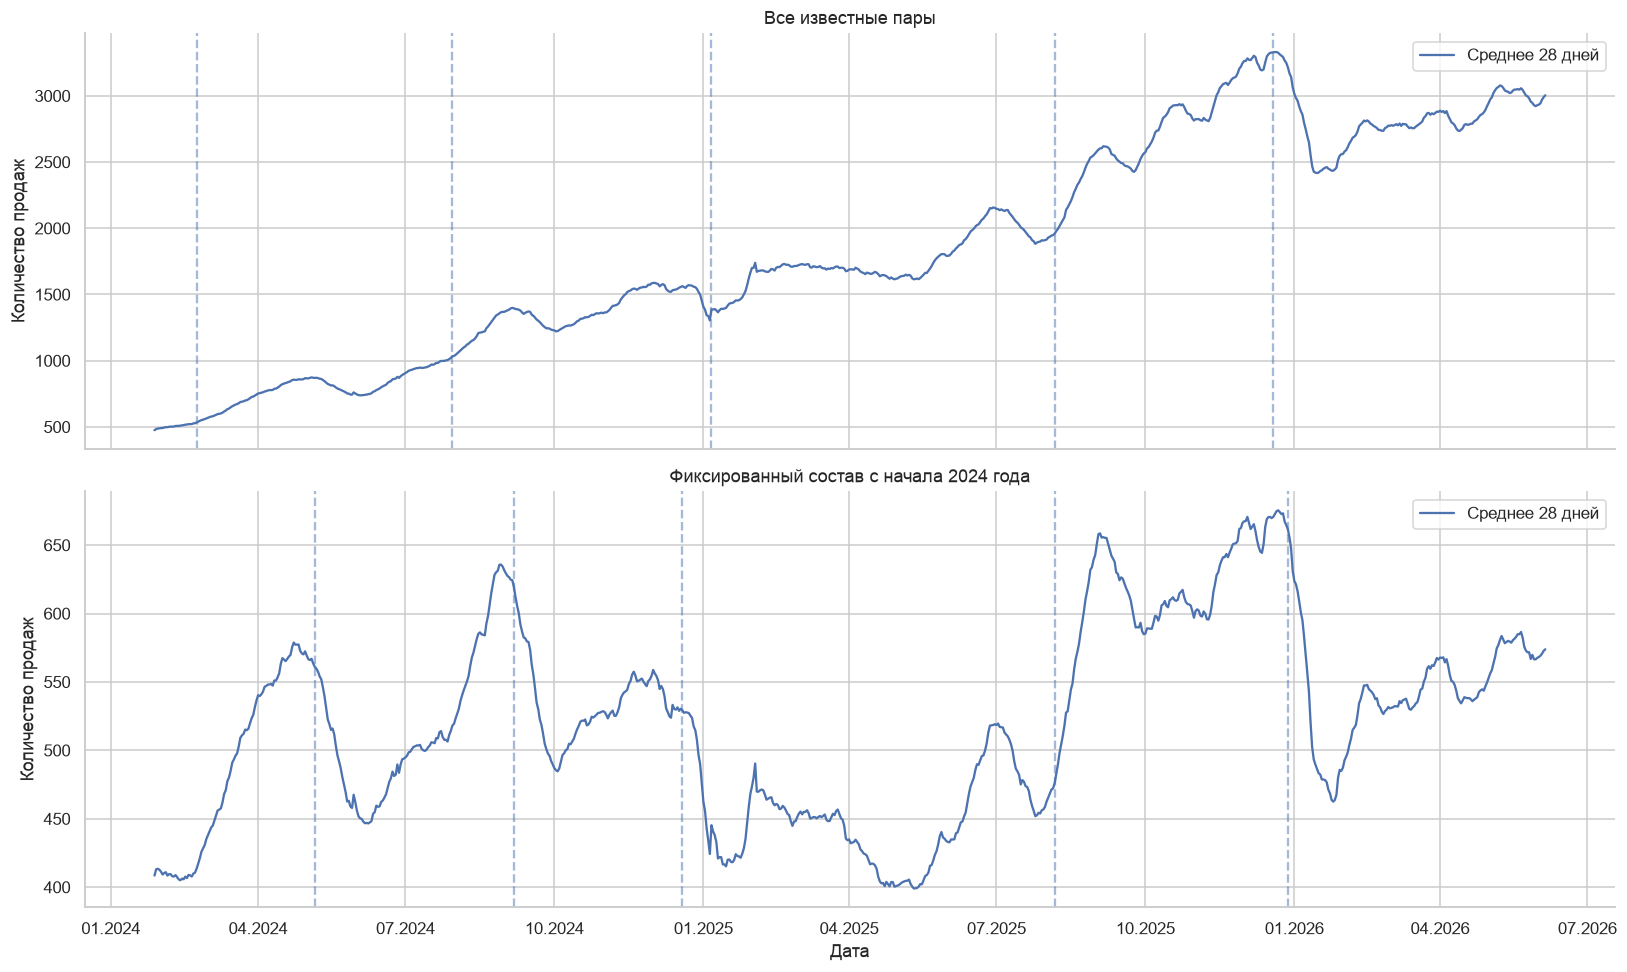

In [8]:
residual=decompositions['all']['log_stl'].resid
median=float(np.median(residual));mad=float(np.median(np.abs(residual-median)))
robust_z=(residual-median)/(1.4826*mad) if mad>0 else pd.Series(np.nan,index=calendar)
anomalies=daily[['quantity','known_pairs','sale_share','positive_stock_share','stock_conflict_share']].copy()
anomalies['robust_z']=robust_z;anomalies['weekday']=[WEEKDAYS[x] for x in calendar.dayofweek]
anomalies=anomalies.loc[robust_z.abs().sort_values(ascending=False).head(15).index]
anomalies.to_csv(OUT/'unusual_dates.csv',index_label='date')
display_ru(anomalies.reset_index(names='date').rename(columns={'known_pairs':'Известных пар','sale_share':'Доля пар с продажами',
    'positive_stock_share':'Доля положительных остатков','stock_conflict_share':'Доля конфликтующих остатков','robust_z':'Устойчивый z','weekday':'День недели'}).round(4))
level_rows=[];fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True)
for ax,(key,y) in zip(axes,SERIES.items()):
    before=y.shift(1).rolling(28,min_periods=28).mean()
    after=y.iloc[::-1].rolling(28,min_periods=28).mean().iloc[::-1]
    change=np.log((after+1)/(before+1)).dropna()
    picked=[]
    for date in change.abs().sort_values(ascending=False).index:
        if all(abs((date-prior).days)>=56 for prior in picked):picked.append(date)
        if len(picked)==5:break
    ax.plot(y.index,y.rolling(28).mean(),label='Среднее 28 дней')
    for date in sorted(picked):
        ax.axvline(date,ls='--',alpha=.5)
        level_rows.append({'series':key,'date':str(date.date()),'mean_before':float(before.loc[date]),'mean_after':float(after.loc[date]),
                           'change_pct':float(100*np.expm1(change.loc[date]))})
    ax.set(title=SERIES_LABELS[key],ylabel='Количество продаж');ax.legend()
axes[-1].set_xlabel('Дата');savefig('10_level_change_candidates.png')
pd.DataFrame(level_rows).to_csv(OUT/'level_change_candidates.csv',index=False)

## 8. Помогает ли сезонность прогнозировать следующие 28 дней

Описательная декомпозиция сама по себе не измеряет качество будущего. Поэтому делаем **восемь последовательных временных проверок** внутри старого обучения. На каждой границе модель видит только более ранние даты и сразу предсказывает следующие 28 дней. Реальные продажи внутри этих 28 дней ей не подставляются.

Сравниваем общий ряд и фиксированный состав. Это прогнозы агрегированных продаж; их MAE нельзя сравнивать с MAE на пару из раздела `training/`.

| Метод | Что делает |
|---|---|
| Последний день | Повторяет последнее наблюдение |
| Последняя неделя | Повторяет последние семь дней по кругу |
| Среднее 28 дней | Один устойчивый уровень на весь горизонт |
| Дни недели за 56 дней | Средний прошлый уровень каждого дня недели |
| Fourier: неделя | Линейный тренд и синусы/косинусы недельного цикла, Ridge ограничивает коэффициенты |
| Fourier: неделя и год | Добавляет две годовые гармоники; проверяем, дают ли они переносимый сигнал |
| ETS с неделей | Экспоненциальное сглаживание уровня, затухающего тренда и недельного рисунка |
| Устойчивый STL + ETS | Убирает локальную недельную сезонность, прогнозирует сглаженный ряд и возвращает сезонность |

Для Fourier, ETS и STL+ETS используем log1p, затем обратное преобразование. Оно может давать смещение в штуках, поэтому сохраняем и общий объём ошибки. ETS — модель экспоненциального сглаживания; она обновляет оценки уровня, тренда и сезона по мере поступления обучающих наблюдений.

**MASE** делит MAE прогноза на среднюю ошибку недельного наивного правила внутри обучения; это позволяет сравнивать разные масштабы рядов. Отдельно считаем отношение к ошибке недельного наивного прогноза на той же будущей проверке. Два знаменателя имеют разный смысл.

В набор включены два перехода через Новый год. Будущие 28-дневные отрезки не пересекаются; среднее по окнам описывает именно этот набор календарных режимов, а не частоту режимов в бизнесе. На ранних границах годовой рисунок оценивается менее чем по полному году — это отдельная проверка его слабой опоры на историю.

Все известные пары 2024-12-15 — все методы выполнены


Все известные пары 2025-02-28 — все методы выполнены


Все известные пары 2025-05-31 — все методы выполнены


Все известные пары 2025-08-31 — все методы выполнены


Все известные пары 2025-11-01 — все методы выполнены


...

Фиксированный состав с начала 2024 года 2025-11-01 — все методы выполнены


Фиксированный состав с начала 2024 года 2025-12-15 — все методы выполнены


Фиксированный состав с начала 2024 года 2026-02-28 — все методы выполнены


Фиксированный состав с начала 2024 года 2026-05-08 — все методы выполнены


,Ряд,Метод,Средняя MAE,Средняя WAPE,Средняя RMSE,Средняя MASE,MAE к последней неделе,Разброс отношения,Побед над последней неделей,Проверок
4,Все известные пары,Среднее 28 дней,357.4499,0.1583,463.8418,1.9950,0.7870,0.1496,7,8
7,Все известные пары,Дни недели за 56 дней,376.5324,0.1647,486.7287,2.0968,0.8667,0.1972,6,8
0,Все известные пары,ETS с неделей,468.9801,0.2068,572.3814,2.5487,0.8677,0.3137,6,8
5,Все известные пары,Устойчивый STL + ETS,453.5368,0.2003,559.4084,2.4843,0.8887,0.1842,6,8
3,Все известные пары,Последний день,509.8348,0.2259,597.8167,2.7729,0.9700,0.3865,6,8
6,Все известные пары,Последняя неделя,480.2188,0.2092,596.2076,2.6182,1.0000,0.0000,0,8
2,Все известные пары,Fourier: неделя и год,458.9777,0.1986,563.5990,2.4780,1.3063,0.7953,4,8
1,Все известные пары,Fourier: неделя,529.7635,0.2275,622.1959,2.7811,1.3855,0.9491,4,8
12,Фиксированный состав с начала 2024 года,Среднее 28 дней,85.8453,0.1692,110.2668,1.3627,0.7380,0.1660,8,8
15,Фиксированный состав с начала 2024 года,Дни недели за 56 дней,88.0045,0.1733,113.2213,1.3968,0.7778,0.1661,7,8


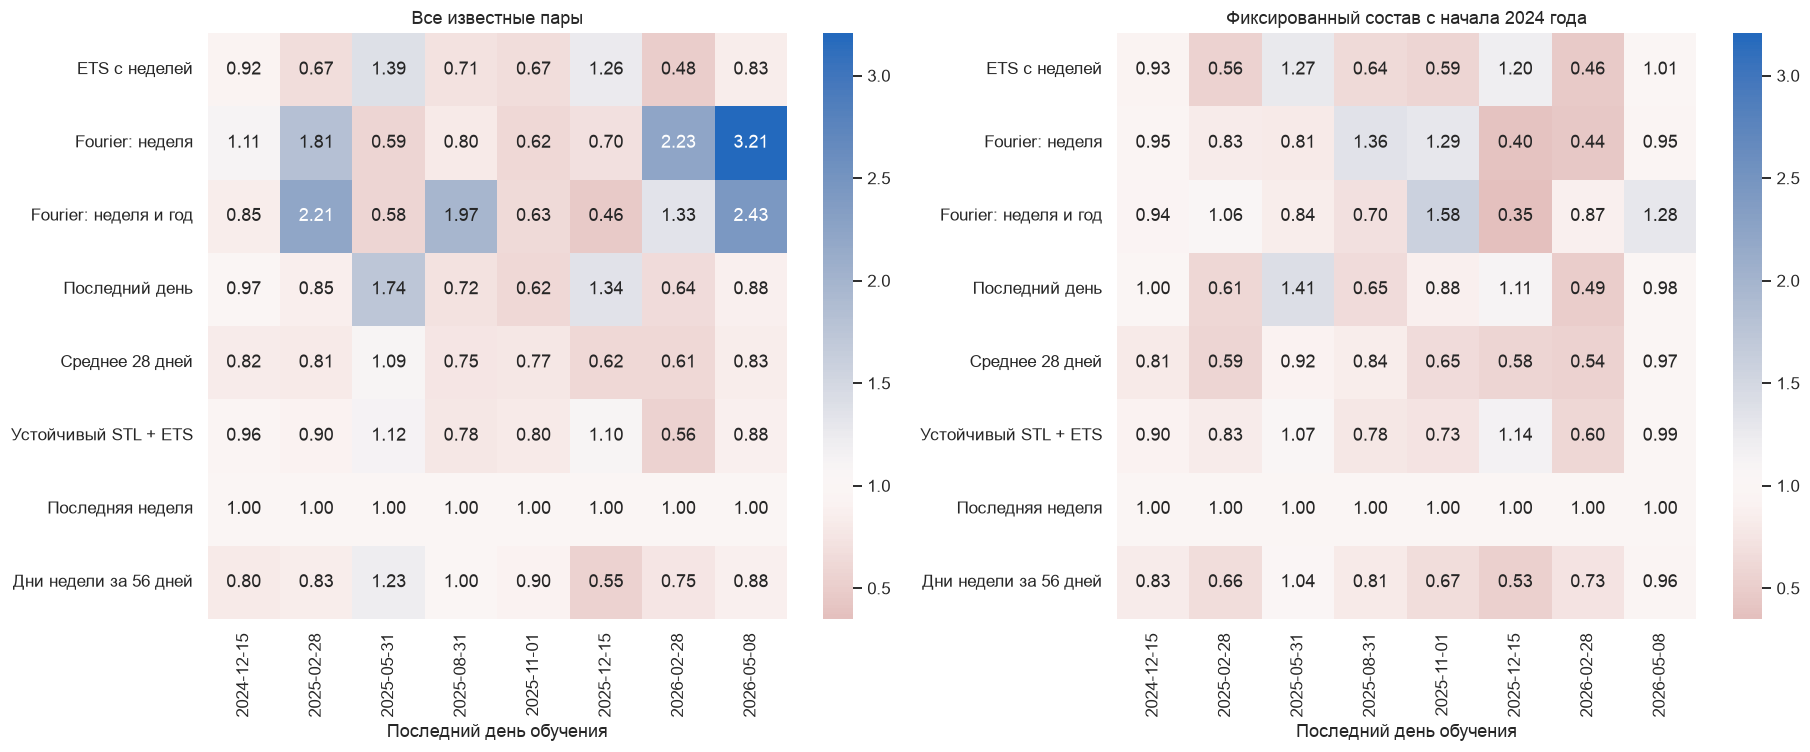

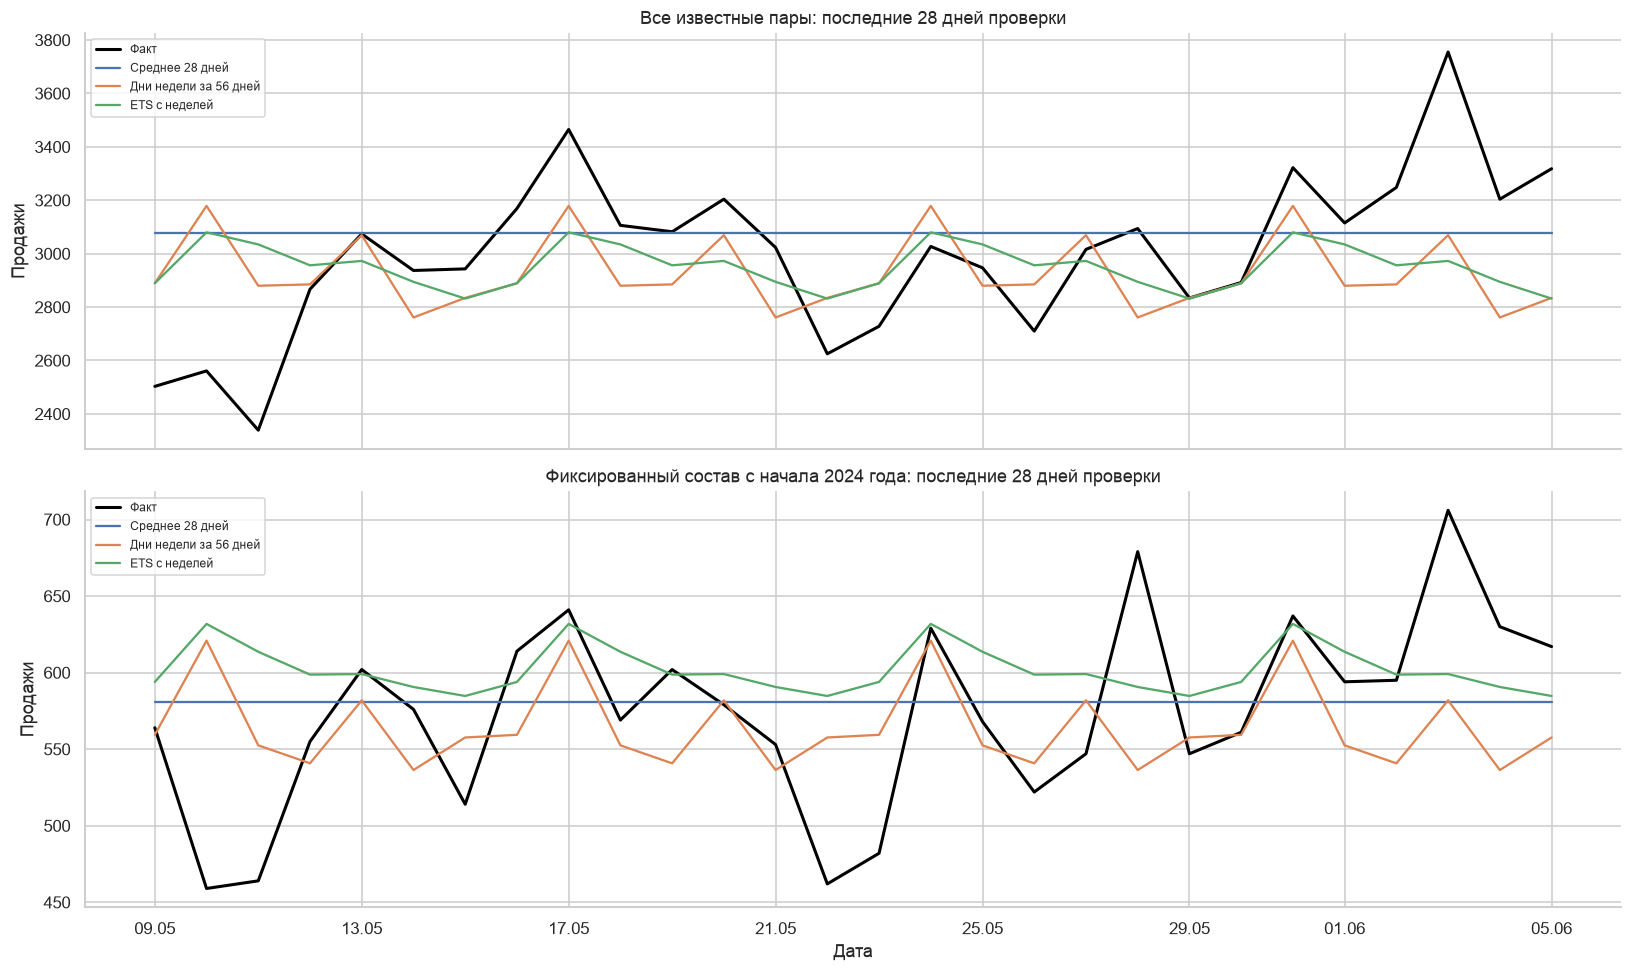

In [9]:
CUTS=pd.to_datetime(['2024-12-15','2025-02-28','2025-05-31','2025-08-31','2025-11-01','2025-12-15','2026-02-28','2026-05-08'])
HORIZON=28
FORECAST_LABELS={'last':'Последний день','week':'Последняя неделя','mean28':'Среднее 28 дней','weekday56':'Дни недели за 56 дней',
                 'fourier_week':'Fourier: неделя','fourier_year':'Fourier: неделя и год','ets':'ETS с неделей','stl_ets':'Устойчивый STL + ETS'}
assert max(CUTS)+pd.Timedelta(days=HORIZON)<=TRAIN_END
assert all((later-earlier).days>=HORIZON for earlier,later in zip(CUTS[:-1],CUTS[1:]))

def fourier_design(dates,annual=False):
    days=(pd.DatetimeIndex(dates)-calendar.min()).days.to_numpy(dtype=float)
    columns=[days/365.2425]
    for period,kmax in [(7,3)]+([(365.2425,2)] if annual else []):
        for k in range(1,kmax+1):columns.extend([np.sin(2*np.pi*k*days/period),np.cos(2*np.pi*k*days/period)])
    return np.column_stack(columns)

def forecast(method,history,future):
    n=len(future);logy=np.log1p(history)
    if method=='last':return np.repeat(history.iloc[-1],n)
    if method=='week':return np.tile(history.iloc[-7:].to_numpy(),int(np.ceil(n/7)))[:n]
    if method=='mean28':return np.repeat(history.iloc[-28:].mean(),n)
    if method=='weekday56':
        profile=history.iloc[-56:].groupby(history.index[-56:].dayofweek).mean()
        return np.array([profile.loc[day] for day in future.dayofweek])
    if method in ['fourier_week','fourier_year']:
        annual=method=='fourier_year'
        model=Ridge(alpha=1.0).fit(fourier_design(history.index,annual),logy)
        return np.maximum(np.expm1(model.predict(fourier_design(future,annual))),0)
    if method=='ets':
        fitted=ExponentialSmoothing(logy,trend='add',damped_trend=True,seasonal='add',seasonal_periods=7,
                                     initialization_method='estimated').fit(optimized=True,use_brute=False)
        return np.maximum(np.expm1(np.asarray(fitted.forecast(n))),0)
    if method=='stl_ets':
        fitted=STLForecast(logy,ExponentialSmoothing,period=7,seasonal=13,trend=91,robust=True,
                           model_kwargs={'trend':'add','damped_trend':True,'initialization_method':'estimated'}).fit(
                               fit_kwargs={'optimized':True,'use_brute':False})
        return np.maximum(np.expm1(np.asarray(fitted.forecast(n))),0)
    raise ValueError(method)

forecast_rows=[];fold_rows=[]
for key,y in SERIES.items():
    for cutoff in CUTS:
        history=y.loc[:cutoff].asfreq('D');future=pd.date_range(cutoff+pd.Timedelta(days=1),periods=HORIZON,freq='D')
        actual=y.reindex(future).to_numpy();assert np.isfinite(actual).all()
        assert history.index.max()<future.min()
        scale=float(history.diff(7).abs().dropna().mean())
        for method in FORECAST_LABELS:
            begin=time.perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always');prediction=np.asarray(forecast(method,history,future),dtype=float)
            assert len(prediction)==HORIZON and np.isfinite(prediction).all() and (prediction>=0).all()
            mae=float(np.abs(actual-prediction).mean());mass=float(actual.sum())
            fold_rows.append({'series':key,'cutoff':str(cutoff.date()),'method':method,'MAE':mae,'WAPE':float(np.abs(actual-prediction).sum()/mass) if mass>0 else np.nan,
                              'RMSE':float(np.sqrt(np.mean((actual-prediction)**2))),'MASE':mae/scale if scale>0 else np.nan,
                              'bias':float(np.mean(prediction-actual)),'seconds':time.perf_counter()-begin,
                              'warning':' | '.join(str(w.message) for w in caught)})
            for date,a,p in zip(future,actual,prediction):forecast_rows.append({'series':key,'cutoff':str(cutoff.date()),'date':str(date.date()),'method':method,'actual':float(a),'prediction':float(p)})
        print(SERIES_LABELS[key],cutoff.date(),'— все методы выполнены',flush=True)
fold_results=pd.DataFrame(fold_rows);predictions=pd.DataFrame(forecast_rows)
reference=fold_results[fold_results.method.eq('week')][['series','cutoff','MAE']].rename(columns={'MAE':'reference_MAE'})
fold_results=fold_results.merge(reference,on=['series','cutoff'],validate='many_to_one')
fold_results['relative_MAE']=fold_results.MAE/fold_results.reference_MAE.replace(0,np.nan)
fold_results.to_csv(OUT/'forecast_fold_metrics.csv',index=False)
predictions.to_csv(OUT/'forecast_predictions.csv',index=False)
summary=fold_results.groupby(['series','method']).agg(mean_MAE=('MAE','mean'),mean_WAPE=('WAPE','mean'),mean_RMSE=('RMSE','mean'),
    mean_MASE=('MASE','mean'),mean_relative_MAE=('relative_MAE','mean'),std_relative_MAE=('relative_MAE','std'),
    wins_vs_week=('relative_MAE',lambda x:int(x.lt(1).sum())),folds=('cutoff','size')).reset_index()
summary.to_csv(OUT/'forecast_summary.csv',index=False)
display_ru(summary.assign(series=summary.series.map(SERIES_LABELS),method=summary.method.map(FORECAST_LABELS)).rename(columns={
    'series':'Ряд','method':'Метод','mean_MAE':'Средняя MAE','mean_WAPE':'Средняя WAPE','mean_RMSE':'Средняя RMSE',
    'mean_MASE':'Средняя MASE','mean_relative_MAE':'MAE к последней неделе','std_relative_MAE':'Разброс отношения',
    'wins_vs_week':'Побед над последней неделей','folds':'Проверок'}).sort_values(['Ряд','MAE к последней неделе']).round(4))
fig,axes=plt.subplots(1,2,figsize=(17,7))
common_min=float(fold_results.relative_MAE.min());common_max=float(fold_results.relative_MAE.max())
for ax,key in zip(axes,SERIES):
    table=fold_results[fold_results.series.eq(key)].pivot(index='method',columns='cutoff',values='relative_MAE')
    table=table.rename(index=FORECAST_LABELS)
    sns.heatmap(table,annot=True,fmt='.2f',center=1,vmin=common_min,vmax=common_max,cmap='vlag_r',ax=ax);ax.set(title=SERIES_LABELS[key],xlabel='Последний день обучения',ylabel='')
savefig('11_forecast_by_cutoff.png')
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True)
for ax,key in zip(axes,SERIES):
    final_cut=str(CUTS[-1].date());g=predictions[(predictions.series.eq(key))&predictions.cutoff.eq(final_cut)]
    actual=g[g.method.eq('week')];ax.plot(pd.to_datetime(actual.date),actual.actual,color='black',lw=2,label='Факт')
    best=summary[summary.series.eq(key)].nsmallest(3,'mean_relative_MAE').method.tolist()
    for method in best:
        row=g[g.method.eq(method)];ax.plot(pd.to_datetime(row.date),row.prediction,label=FORECAST_LABELS[method])
    ax.set(title=SERIES_LABELS[key]+': последние 28 дней проверки',ylabel='Продажи');ax.legend(fontsize=8)
axes[-1].set_xlabel('Дата');savefig('12_forecast_examples.png')

## 9. Что переносить в дальнейшую работу

Из декомпозиции можно получить гипотезы о временах года, днях недели и общих режимах. Для рабочего прогноза их нужно подтвердить на нескольких границах и посчитать только из доступной к дате истории. Гибкие компоненты STL/MSTL из полного ряда не являются готовыми входами для обучения на каждой его строке.

Кандидаты для следующей FE-итерации: отдельные недельные профили товара/склада, взаимодействия с календарём, длинные и событийные окна, календарные гармоники с проверкой устойчивости. Наличие годовой компоненты в MSTL само по себе не подтверждает пользу годовых признаков.

Отчёт ниже заполняется из фактических результатов. Оценки общего ряда описывают временную структуру; они не являются улучшением качества прогноза каждой пары и не заменяют официальную постановку.

In [10]:
# Формируем короткий отчёт с числами, а не общими обещаниями.
first=daily.iloc[:56].mean(numeric_only=True);last=daily.iloc[-56:].mean(numeric_only=True)
report=['# Время и сезонность: результаты исследования','',
    f"Период: {calendar.min().date()} — {calendar.max().date()}, {len(calendar)} дней. Известных пар к концу: {int(daily.known_pairs.iloc[-1])}; фиксированный состав: {len(cohort)} пар, выбранных до начала 2024 года.",
    '',f"За последние 56 дней относительно первых 56 средние продажи всех известных пар изменились в {last.quantity/first.quantity:.2f} раза. Известных пар стало в {last.known_pairs/first.known_pairs:.2f} раза больше. Продажи на известную пару: {first.qty_per_known_pair:.3f} → {last.qty_per_known_pair:.3f}. Это изменение смеси товаров, частоты и размера продаж; его нельзя целиком назвать сезонностью.",
    '',f"Продажи на пару фиксированного состава: {first.qty_per_fixed_pair:.3f} → {last.qty_per_fixed_pair:.3f}. Фиксированный состав не отбирался по будущим продажам, но описывает только старый ассортимент.",
    '', '## Декомпозиция','']
for key in SERIES:
    r=decompositions[key]['mstl']
    report.append(f"{SERIES_LABELS[key]}: описательная сила недельной компоненты MSTL = {strength(r.seasonal.iloc[:,0],r.resid):.3f}, годовой = {strength(r.seasonal.iloc[:,1],r.resid):.3f}. Это внутривыборочная характеристика, а не качество будущего.")
report+=['','Годовой рисунок основан лишь на двух полных календарных годах; высокий показатель MSTL не доказывает его устойчивость. Почти нулевой остаток на отдельных длинных участках указывает на гибкость разложения при малом числе повторов. Центрированные компоненты нельзя переносить в FE без пересчёта из прошлого.','',
         '## Восемь проверок прогноза на 28 дней','', '| Ряд | Лучший по среднему отношению MAE | Отношение к последней неделе | Побед из 8 |','|---|---|---:|---:|']
for key in SERIES:
    best=summary[summary.series.eq(key)].sort_values('mean_relative_MAE').iloc[0]
    report.append(f"| {SERIES_LABELS[key]} | {FORECAST_LABELS[best.method]} | {best.mean_relative_MAE:.3f} | {int(best.wins_vs_week)} |")
report+=['','Отношение ниже 1 означает меньшую ошибку, чем повторение последней недели на той же проверке. Оно усредняется по восьми разным границам; отдельные окна могут давать иной результат. MAE агрегированного ряда нельзя сравнивать с MAE на пару.',
         '', '## Годовые гармоники: проверка вместо предположения','']
for key in SERIES:
    subset=fold_results[fold_results.series.eq(key)]
    p=subset.pivot(index='cutoff',columns='method',values='MAE')
    ratio=p.fourier_year/p.fourier_week
    report.append(f"{SERIES_LABELS[key]}: неделя + год против одной недели — среднее отношение MAE {ratio.mean():.3f}; улучшение в {int(ratio.lt(1).sum())} из {len(ratio)} окон.")
report+=['',f"У четырёх групп недельных профилей товаров silhouette = {silhouette:.3f}. Это диагностическая оценка разделимости, а не доказательство природных групп. В выборке для формы минимум 365 дней и 60 дней продаж на товар.",
         '', 'Необычные даты и кандидаты смены уровня сохранены отдельно; они не удалялись из истории. Совпадения со складскими показателями требуют предметной проверки.',
         '', 'Следующая итерация: проверять временные признаки на прогнозе каждой пары, сохранять исходную временную схему и получить официальный горизонт и метрику. Текущий анализ не использует поздние июньские и июльские метки.']
(ROOT/'research/time_analysis_results.md').write_text('\n'.join(report)+'\n')
display(Markdown('\n'.join(report)))
versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','scipy','statsmodels','matplotlib','seaborn','scikit-learn','pyarrow','nbclient']}
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'versions':versions,'seed':SEED},indent=2))
verification={'train_end':str(TRAIN_END.date()),'days':len(calendar),'cohort_pairs':len(cohort),'series':list(SERIES_LABELS.values()),
    'cutoffs':[str(c.date()) for c in CUTS],'forecast_rows':len(predictions),'evaluations':len(fold_results),
    'checks':['Непрерывная дневная шкала','Пары известны до даты прогноза','Фиксированный состав выбран до начала истории',
              'Проверена точная сумма компонент декомпозиции','Прогнозы вычислены только после конца своего обучения',
              'Все прогнозы конечны и неотрицательны','Все окна завершены внутри старого обучения','Будущие окна не пересекаются между собой']}
assert len(fold_results)==len(SERIES)*len(CUTS)*len(FORECAST_LABELS)
assert (pd.to_datetime(predictions.date)>pd.to_datetime(predictions.cutoff)).all()
assert pd.to_datetime(predictions.date).max()<=TRAIN_END
assert predictions.prediction.ge(0).all() and np.isfinite(predictions.prediction).all()
(OUT/'verification.json').write_text(json.dumps(verification,ensure_ascii=False,indent=2))
print('Проверки временных границ, компонент и прогнозов пройдены.')

# Время и сезонность: результаты исследования

Период: 2024-01-01 — 2026-06-05, 887 дней. Известных пар к концу: 8775; фиксированный состав: 1529 пар, выбранных до начала 2024 года.

За последние 56 дней относительно первых 56 средние продажи всех известных пар изменились в 5.96 раза. Известных пар стало в 3.34 раза больше. Продажи на известную пару: 0.199 → 0.347. Это изменение смеси товаров, частоты и размера продаж; его нельзя целиком назвать сезонностью.

Продажи на пару фиксированного состава: 0.271 → 0.378. Фиксированный состав не отбирался по будущим продажам, но описывает только старый ассортимент.

## Декомпозиция

Все известные пары: описательная сила недельной компоненты MSTL = 0.179, годовой = 0.838. Это внутривыборочная характеристика, а не качество будущего.
Фиксированный состав с начала 2024 года: описательная сила недельной компоненты MSTL = 0.432, годовой = 0.920. Это внутривыборочная характеристика, а не качество будущего.

Годовой рисунок основан лишь на двух полных календарных годах; высокий показатель MSTL не доказывает его устойчивость. Почти нулевой остаток на отдельных длинных участках указывает на гибкость разложения при малом числе повторов. Центрированные компоненты нельзя переносить в FE без пересчёта из прошлого.

## Восемь проверок прогноза на 28 дней

| Ряд | Лучший по среднему отношению MAE | Отношение к последней неделе | Побед из 8 |
|---|---|---:|---:|
| Все известные пары | Среднее 28 дней | 0.787 | 7 |
| Фиксированный состав с начала 2024 года | Среднее 28 дней | 0.738 | 8 |

Отношение ниже 1 означает меньшую ошибку, чем повторение последней недели на той же проверке. Оно усредняется по восьми разным границам; отдельные окна могут давать иной результат. MAE агрегированного ряда нельзя сравнивать с MAE на пару.

## Годовые гармоники: проверка вместо предположения

Все известные пары: неделя + год против одной недели — среднее отношение MAE 1.053; улучшение в 5 из 8 окон.
Фиксированный состав с начала 2024 года: неделя + год против одной недели — среднее отношение MAE 1.152; улучшение в 3 из 8 окон.

У четырёх групп недельных профилей товаров silhouette = 0.111. Это диагностическая оценка разделимости, а не доказательство природных групп. В выборке для формы минимум 365 дней и 60 дней продаж на товар.

Необычные даты и кандидаты смены уровня сохранены отдельно; они не удалялись из истории. Совпадения со складскими показателями требуют предметной проверки.

Следующая итерация: проверять временные признаки на прогнозе каждой пары, сохранять исходную временную схему и получить официальный горизонт и метрику. Текущий анализ не использует поздние июньские и июльские метки.

Проверки временных границ, компонент и прогнозов пройдены.
